# Evidence-layer hybrid for fraud detection — final codebase (IEEE-CIS)

**The model:** two neural component models — **TabM+G** (what the transaction looks like) and the **deviation model (+G)** (how it differs from the same user's past) — both fed by one past-only **evidence layer** (entity memory, deviation features, neighbour/graph features), combined by a **fixed weighted average** of their scores.

**Baselines:** LightGBM on raw features, LightGBM on raw features retrained every 30 days, and **LightGBM+** (raw features + the same evidence layer).

**Analyses:** what each part of the evidence layer adds; label delay 0 / 7 / 30 / 60 days; TabNet vs TabM; graph as a model vs as features; evidence gate vs fixed weighted average; calibration.

## How to run — one seed per run
1. Cell 1: set `SEED`. Order: **42, then 7, then 123** (fixed in advance).
2. Run cells 1 → 19. Every cell saves to Drive and skips finished work; after a disconnect, run cells 1–2 and continue.
3. Cell 21 = report over all stored seeds, cell 22 = figures, cell 23 = one block of numbers to copy back. Later sessions: cell 1 + cells 21–23 only (no GPU).

Results are saved as `store_final/seed_<SEED>_metrics.csv`, `_questions.csv`, `_gate.csv`, `_calibration.csv`; scores as `score_<model>_s<SEED>.npy`. Runs finished in v6/v7 (same file names) are reused automatically.

`RUN_ABLATIONS = False` in cell 1 trains only the model and the three baselines (much faster); the analysis tables then stay empty for that seed.

| Cell | Job | Cell | Job |
|---|---|---|---|
| 1–2 | settings, dataset adapter, helpers, models | 14 | LightGBM baselines + evidence-layer ablations |
| 4 | architecture diagram | 15 | label-delay sweep (first seed only) |
| 6–11 | load, preprocess, evidence layer, leak checks (built once) | 16 | the two component models (TabM+G, deviation +G) |
| 12 | neighbour (graph) features (built once) | 17 | ablation models (TabM+, deviation, graph, TabNet) |
| | | 18 | fixed weighted average (the model) + gate and other ablation hybrids |
| | | 19 | evaluate SEED → Drive |
| | | 21 · 22 · 23 | report · figures · numbers to copy back |

In [41]:
# ── 1 · Setup: run first in every session ──
try:
    from google.colab import drive; drive.mount('/content/drive')
except ImportError: pass
import subprocess, sys
try: import pytorch_tabnet                      # Study A needs it; Colab does not ship it
except ImportError: subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pytorch-tabnet'], check=False)
import warnings; warnings.filterwarnings('ignore')
import os, gc, json, glob, math, time, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F, lightgbm as lgb
from sklearn.metrics import average_precision_score as ap, roc_auc_score as auc
from sklearn.linear_model import LogisticRegression as LR
try: display
except NameError: display = print
pd.set_option('display.max_columns', 30, 'display.width', 220)

# ================= THE ONLY LINE YOU CHANGE BETWEEN RUNS =================
SEED = 123                  # run once per seed, in this order: 42, 7, 123 (fixed in advance -- never chosen by results)
# =========================================================================
SEEDS_PLAN = [42, 7, 123]
RUN_ABLATIONS = True        # TabNet, graph model, no-graph models, evidence-layer ablations (needed for the analysis tables)
RUN_DELAY_SWEEP = SEED == SEEDS_PLAN[0]   # LightGBM+ at label delays 0 / 7 / 60 days: once, on the first seed
SWEEP_DELAYS = [0, 7, 60]
RT_DAYS = 30                # retrained-LightGBM baseline: retrain every RT_DAYS on visible labels only

DATA_DIR = '/content/drive/MyDrive/CIS FRAUD DETECTION/'
WORK = DATA_DIR + 'egh_v3/'; STORE = 'store_final/'; os.makedirs(WORK + STORE, exist_ok=True)   # caches shared with v6/v7; results in store_final/
DELAY = 30                  # label delay in days for the main model
LAM_TAB, LAM_GNN = .5, .02  # pruning strength: TabM+ feature gates, graph edge gates
N_FOLDS = 4                 # blocked cross-fitting folds per component model

# ---------- DATASET ADAPTER (IEEE-CIS): the column roles below + cell 6 (loading) are the only dataset-specific parts ----------
ENT = ['uid', 'card1', 'card_bundle', 'addr1', 'P_emaildomain', 'R_emaildomain', 'DeviceInfo', 'id_31']  # entity memory
GRAPH_ENT, K = ['card1', 'addr1', 'DeviceInfo'], 8   # cross-user relations; K recent + K label-visible neighbours each
L_SEQ = 16                  # past transactions of the same uid the deviation model attends over
SEQ_COLS = ['TransactionAmt', 'dist1', 'C1', 'C2', 'C5', 'C6', 'C9', 'C11', 'C13', 'C14',
            'D1', 'D2', 'D3', 'D4', 'D10', 'D15', 'hour_sin', 'hour_cos', 'missing']
DEV_NEW = ['DeviceInfo', 'P_emaildomain', 'R_emaildomain', 'id_31', 'card_bundle', 'ProductCD']
EXTRA_TAB = ['card2', 'card3', 'card5', 'addr2', 'id_30', 'id_33']
NBIN, ZD = 8, 16
HC_FREQ = ['card1', 'card2', 'card3', 'card5', 'addr1', 'addr2', 'P_emaildomain', 'R_emaildomain', 'DeviceInfo', 'id_31', 'card_bundle', 'uid']
HC_CAT = ['card1', 'card2', 'card5', 'addr1', 'P_emaildomain', 'R_emaildomain', 'DeviceInfo', 'id_31', 'card_bundle']
MIN_CAT = 30
FAM = ['0', '1-5', '6-20', '21-100', '101+']

TAG = f'd{DELAY}'; LT = f'l{LAM_TAB}'
XT = f'{TAG}_final_f{N_FOLDS}'                      # combiners trained in this notebook
DL = DELAY * 86400
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
P = lambda f: WORK + f
have = lambda *fs: all(os.path.exists(P(f)) for f in fs)
sig = lambda s: 1 / (1 + np.exp(-s))
fam_bin = lambda cnt: np.digitize(cnt, [1, 6, 21, 101])

# ---------- model registry: key -> file stem (score_<stem>_s<seed>.npy). Stems match v6/v7, so finished runs are reused ----------
EXPERT_STEM = {'tabpg': f'tabpg_{TAG}_f{N_FOLDS}_{LT}', 'devg': f'devg_{TAG}_f{N_FOLDS}',                 # the two component models
               'tabp': f'tabp_{TAG}_f{N_FOLDS}_{LT}', 'dev': f'dev6_{TAG}_f{N_FOLDS}',                    # ablation: same models, no graph features
               'gnn': f'gnn6_{TAG}_f{N_FOLDS}_l{LAM_GNN}', 'tabnet': f'tabnet_{TAG}_f{N_FOLDS}'}          # ablation: graph model, TabNet
LGB_STEM = {'lgb_raw': 'lgb_raw', 'lgb_rt': f'lgb_raw_rt{RT_DAYS}_{TAG}', 'lgb_g': f'lgb_plusg_{TAG}',  # baselines; lgb_g = LightGBM+
            'lgb_plus': f'lgb_plus_{TAG}', 'lgb_mem': f'lgb_mem_{TAG}', 'lgb_dev': 'lgb_devonly', 'lgb_nolabel': f'lgb_nolabel_{TAG}'}
LGB_STEM.update({f'lgb_plus_d{d}': f'lgb_plus_d{d}' for d in SWEEP_DELAYS})
COMBOS = {'hyb': ('fixed', ['tabpg', 'devg']),        # THE MODEL: two component models with graph features, fixed weighted average
          'hyb_gate': ('evid', ['tabpg', 'devg']),      # ablation: same models, evidence gate
          'hyb_tg': ('fixed', ['tabpg', 'dev']),        # ablation: graph features in TabM only
          'hyb_nog': ('fixed', ['tabp', 'dev']),        # ablation: no graph information anywhere
          'hyb_gexp': ('fixed', ['tabp', 'dev', 'gnn']),     # ablation: graph as a third component model (the v6/v7 design)
          'hyb_both': ('fixed', ['tabpg', 'devg', 'gnn']),   # ablation: graph as features AND as a component model
          'hyb_tabnet': ('fixed', ['tabnet', 'dev'])}   # ablation: TabNet instead of TabM (compare with hyb_nog)

def model_files():
    m = dict(LGB_STEM); m.update(EXPERT_STEM); m.update({k: f'{k}_{v[0]}_{XT}' for k, v in COMBOS.items()}); return m
score = lambda key, sd=None: np.load(P(f'score_{model_files()[key]}_s{SEED if sd is None else sd}.npy'))
has_score = lambda key, sd=None: have(f'score_{model_files()[key]}_s{SEED if sd is None else sd}.npy')

# ---------- data helpers (unchanged from v6) ----------
def reduce_mem(df):
    """Downcast numbers to the smallest safe type and turn strings into categories."""
    mb = df.memory_usage().sum() / 2**20
    for c in df.columns:
        t = str(df[c].dtype)
        if t == 'category': continue
        if not pd.api.types.is_numeric_dtype(df[c]): df[c] = df[c].astype('category')
        elif t.startswith('int'): df[c] = pd.to_numeric(df[c], downcast='integer')
        elif t.startswith('float'): df[c] = df[c].astype(np.float32)
    print(f'memory {mb:.0f} MB -> {df.memory_usage().sum() / 2**20:.0f} MB'); return df

def common():
    y, split = np.load(P('y.npy')), np.load(P('split.npy'))     # split: 0 train, 1 stop, 2 calib, 3 test
    idx = [torch.tensor(np.where(split == k)[0], device=DEV) for k in range(4)]
    return y, split, torch.tensor(y, device=DEV), idx

def evidence(H=None, tag=TAG):
    """Evidence signals (gate inputs): how much is known about this transaction, never what it looks like."""
    H = np.load(P(f'hist_{tag}.npy'), mmap_mode='r') if H is None else H
    nr, nk = np.load(P('nb_recent.npy'), mmap_mode='r'), np.load(P(f'nb_known_{tag}.npy'), mmap_mode='r')
    ev = np.c_[H[:, 0, 0], H[:, 0, 1], H[:, 0, 5], H[:, 1, 0], np.load(P('d1.npy')), np.load(P('miss.npy')),
               np.load(P('uid_missing.npy')), np.log1p((nr >= 0).sum(2)), np.log1p((nk >= 0).sum(2))].astype(np.float32)
    ntr = int((np.load(P('split.npy')) == 0).sum())
    return (ev - ev[:ntr].mean(0)) / (ev[:ntr].std(0) + 1e-6)

def raw_X():
    df = pd.read_parquet(P('base.parquet')).drop(columns=['TransactionID', 'isFraud', 'TransactionDT', 'split', 'uid', 'card_bundle', 'D1n'])
    for c in df.select_dtypes('category'): df[c] = df[c].cat.codes.astype(np.int16)
    return df

def lgb_X(mem=True, dev=True, label_free=False, nbf=False, tag=TAG):
    """LightGBM inputs = raw features + the chosen parts of the evidence layer (Study D).
    mem: entity memory + evidence signals | dev: deviation features | label_free: memory WITHOUT its two label
    columns (fraud rate, #labels visible) | nbf: neighbour (graph) features. lgb_X() == v6 LightGBM+."""
    X = raw_X(); parts = []
    if mem:
        H = np.load(P(f'hist_{tag}.npy')).astype(np.float32)
        parts += [(H[:, :, [0, 1, 2, 5]] if label_free else H).reshape(len(X), -1), evidence(H, tag)]
    if dev: parts.append(np.load(P('dev.npy')))
    if nbf: parts.append(np.load(P(f'nbf_{tag}.npy')))
    if not parts: return X
    M = np.concatenate(parts, 1)
    return pd.concat([X, pd.DataFrame(M, columns=[f'm{i}' for i in range(M.shape[1])])], axis=1)

def run_lgb(name, X, y, tr, va, sd=None):
    """LightGBM for one seed, early-stopped on rows `va`. Saves raw scores for every row as score_<name>_s<seed>.npy."""
    sd = SEED if sd is None else sd; f = f'score_{name}_s{sd}.npy'
    if have(f): return
    prm = dict(objective='binary', learning_rate=.05, num_leaves=256, min_child_samples=100, feature_fraction=.5,
               bagging_fraction=.8, bagging_freq=1, lambda_l2=1, seed=sd, verbose=-1)
    t0 = time.time()
    m = lgb.train(prm, lgb.Dataset(X[tr], y[tr]), 3000, valid_sets=[lgb.Dataset(X[va], y[va])],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    p = m.predict(X, raw_score=True, num_iteration=m.best_iteration).astype(np.float32); np.save(P(f), p)
    json.dump({'sec': time.time() - t0}, open(P(f'time_{name}_s{sd}.json'), 'w'))
    te = np.load(P('split.npy')) == 3
    print(f'{name} seed {sd}: iters {m.best_iteration}, test PR-AUC {ap(y[te], p[te]):.4f}  ROC-AUC {auc(y[te], p[te]):.4f}'); del m; gc.collect()

# ---------- training helpers (v6 + timing + per-model fit settings) ----------
@torch.no_grad()
def predict(m, bf, idx, bs=8192):
    """Always returns a LIST of arrays: [logit, *extras]."""
    m.eval(); out = []
    for i in range(0, len(idx), bs):
        o = m(*bf(idx[i:i + bs])); o = o if isinstance(o, tuple) else (o,)
        out.append([v.float().cpu() for v in o])
    return [torch.cat(v).numpy() for v in zip(*out)]

def fit(m, bf, tr, va, yg, epochs=30, bs=2048, lr=1e-3, patience=3):
    """Mini-batch training with early stopping on stop-set PR-AUC; keeps the best weights. Models with a `warm`
    attribute (sparsity ramp) are only checkpointed after warm-up."""
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-5); best, bad, st = -1, 0, None
    yv, warm = yg[va].cpu().numpy(), getattr(m, 'warm', 0)
    for ep in range(epochs):
        if hasattr(m, 'epoch_hook'): m.epoch_hook(ep)
        m.train(); perm = tr[torch.randperm(len(tr), device=tr.device)]
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]; o = m(*bf(b)); o = o[0] if isinstance(o, tuple) else o
            t = yg[b].float(); t = t[:, None].expand_as(o) if o.dim() == 2 else t
            loss = F.binary_cross_entropy_with_logits(o, t) + (m.reg() if hasattr(m, 'reg') else 0)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 5.); opt.step()
        p = predict(m, bf, va)[0]; s = ap(yv, p.mean(1) if p.ndim == 2 else p)
        print(f'  epoch {ep}  stop PR-AUC {s:.4f}' + (f'  gates open {float(m.pen):.2f}' if hasattr(m, 'pen') else ''))
        if ep < warm and ep < epochs - 1: continue
        if s > best: best, bad, st = s, 0, {k: v.clone() for k, v in m.state_dict().items()}
        elif (bad := bad + 1) >= patience: break
    if st is not None: m.load_state_dict(st)
    return best

def folds():
    """Fold id (0..N_FOLDS-1) of every training row as contiguous time blocks; -1 for stop / calib / test rows."""
    split = np.load(P('split.npy')); ntr = int((split == 0).sum()); f = np.full(len(split), -1, np.int8)
    f[:ntr] = np.arange(ntr) * N_FOLDS // ntr; return f

def crossfit(name, make, bf, yg, post, **fit_kw):
    """Blocked cross-fitting: fold k trains on all other training blocks, early-stops on the stop split, predicts
    block k (out of fold) + stop / calib / test. Gives an out-of-fold score for every training row (the combiner's
    training data) and, for later rows, the average of N_FOLDS models. Saves training seconds per fold."""
    y, split, _, idx = common(); fo = folds(); n = len(y); later = np.where(split >= 1)[0]; sd = SEED
    if have(f'score_{name}_s{sd}.npy'): return
    for k in range(N_FOLDS):
        f = f'fold_{name}_k{k}_s{sd}.npz'
        if have(f): continue
        tr = np.where((fo >= 0) & (fo != k))[0]; rows = np.r_[np.where(fo == k)[0], later]
        print(f'{name} | seed {sd} | fold {k + 1}/{N_FOLDS}: {len(tr):,} training rows'); torch.manual_seed(sd * 100 + k)
        t0 = time.time(); m = make().to(DEV); fit(m, bf, torch.tensor(tr, device=DEV), idx[1], yg, **fit_kw)
        L, U = post(predict(m, bf, torch.tensor(rows, device=DEV)))
        np.savez(P(f), rows=rows, L=L.astype(np.float32), U=U.astype(np.float32), sec=time.time() - t0); del m; torch.cuda.empty_cache()
    L, U, sec = np.zeros(n, np.float32), np.zeros(n, np.float32), 0.
    for k in range(N_FOLDS):
        z = np.load(P(f'fold_{name}_k{k}_s{sd}.npz')); r, nk = z['rows'], int((fo == k).sum())
        L[r[:nk]], U[r[:nk]] = z['L'][:nk], z['U'][:nk]
        L[later] += z['L'][nk:] / N_FOLDS; U[later] += z['U'][nk:] / N_FOLDS
        sec += float(z['sec']) if 'sec' in z.files else np.nan
    np.save(P(f'u_{name}_s{sd}.npy'), U); np.save(P(f'score_{name}_s{sd}.npy'), L)
    json.dump({'sec': sec}, open(P(f'time_{name}_s{sd}.json'), 'w'))
    te = split == 3
    print(f'{name} seed {sd}: test PR-AUC {ap(y[te], L[te]):.4f}  ROC-AUC {auc(y[te], L[te]):.4f}')

def lgb_crossfit(name, X, y):
    """LightGBM+ with the SAME blocked folds and bagging as the component models (bagging helps trees too)."""
    split = np.load(P('split.npy')); fo = folds(); sd = SEED; later = split >= 1
    if have(f'score_{name}_s{sd}.npy'): return
    L = np.zeros(len(y), np.float32)
    for k in range(N_FOLDS):
        run_lgb(f'{name}_k{k}', X, y, (fo >= 0) & (fo != k), split == 1)
        p = np.load(P(f'score_{name}_k{k}_s{sd}.npy')); L[fo == k] = p[fo == k]; L[later] += p[later] / N_FOLDS
    np.save(P(f'score_{name}_s{sd}.npy'), L); print(f'{name} seed {sd}: test PR-AUC {ap(y[split == 3], L[split == 3]):.4f}')

def ece(y, p, n=15):
    b = np.minimum((p * n).astype(int), n - 1)
    return sum(abs(y[b == i].mean() - p[b == i].mean()) * (b == i).mean() for i in range(n) if (b == i).any())
recall_at = lambda y, p, q: y[np.argsort(-p)[:max(1, int(len(p) * q))]].sum() / max(y.sum(), 1)
assert SEED in SEEDS_PLAN, f'SEED must be one of {SEEDS_PLAN}'
print('device:', DEV, '| work dir:', WORK, '| SEED this run:', SEED, '| ablations:', RUN_ABLATIONS, '| delay sweep:', RUN_DELAY_SWEEP,
      '| seeds already stored:', sorted(int(f.split('_')[-2]) for f in glob.glob(P(STORE + 'seed_*_metrics.csv'))))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda | work dir: /content/drive/MyDrive/CIS FRAUD DETECTION/egh_v3/ | SEED this run: 123 | ablations: True | delay sweep: False | seeds already stored: [7, 42, 123]


In [43]:
# ── 2 · Definitions: run every session ──
# ---------- relational indexes (all past-only; rows are time-sorted) ----------
def entity_hist(g, t, y, la, delay, ntr, prior):
    """For each row, what was known about its entity value from EARLIER rows only. Labels count only once older
    than the reporting delay. Columns: log count, log age (days), mean log-amount, smoothed fraud rate, log #labels
    visible, first sighting. Rows with a missing entity value (g < 0) get zeros."""
    n = len(g); o = np.argsort(g, kind='stable'); gs, ts = g[o], t[o]
    st = np.maximum.accumulate(np.where(np.r_[True, gs[1:] != gs[:-1]], np.arange(n), 0))   # group start
    cnt = np.arange(n) - st                                                                   # earlier sightings
    ca = np.r_[0, np.cumsum(la[o], dtype=np.float64)]; mamt = (ca[:-1] - ca[st]) / np.maximum(cnt, 1)
    if delay == 'leak':        # leaky control: every training label of the entity, future ones included
        gi, trm = g + 1, (np.arange(n) < ntr).astype(np.float64)
        nl, fs = np.bincount(gi, trm)[gi][o], np.bincount(gi, y * trm)[gi][o]
    else:
        key = gs.astype(np.int64) * 10**9 + ts
        pos = np.maximum(np.searchsorted(key, key - int(delay * 86400) - 1, 'right'), st)
        cy = np.r_[0, np.cumsum(y[o])]; nl, fs = pos - st, cy[pos] - cy[st]
    Fs = np.c_[np.log1p(cnt) / 5, np.log1p((ts - ts[st]) / 86400) / 5, mamt,
               (fs + 10 * prior) / (nl + 10) * 10, np.log1p(nl) / 5, cnt == 0]
    out = np.empty(Fs.shape, np.float32); out[o] = Fs; out[g < 0] = 0
    c = np.empty(n, np.int64); c[o] = cnt; c[g < 0] = 0
    return out, c

def group_order(g, t):
    """Stable sort by group keeps each group in time order. Returns the order o, each sorted position's group
    start st, and the sorted key (group, time) for window searches."""
    n = len(g); o = np.argsort(g, kind='stable'); gs = g[o]
    st = np.maximum.accumulate(np.where(np.r_[True, gs[1:] != gs[:-1]], np.arange(n), 0))
    return o, st, gs.astype(np.int64) * 10**9 + t[o]

def earlier_rows(g, t, k, delay_s=None):
    """Up to k earlier rows of the same group for every row (row ids, most recent first, -1 = none).
    delay_s=None: the most recent earlier rows. delay_s=x: only rows with t < t_row - x (label already visible)."""
    o, st, key = group_order(g, t); n = len(g)
    top = np.arange(n) if delay_s is None else np.maximum(np.searchsorted(key, key - delay_s, 'left'), st)
    j = top[:, None] - 1 - np.arange(k)[None]
    res = np.where(j >= st[:, None], o[np.maximum(j, 0)], -1).astype(np.int32)
    out = np.empty_like(res); out[o] = res; out[g < 0] = -1
    return out

def cross_user(g, uid, t, k, delay_s=None, over=3):
    """Like earlier_rows, but skips rows of the SAME uid (those belong to the deviation expert): takes 3k candidates,
    drops same-uid ones, keeps the first k."""
    c = earlier_rows(g, t, k * over, delay_s)
    valid = (c >= 0) & ~((uid[np.maximum(c, 0)] == uid[:, None]) & (uid[:, None] >= 0))
    o = np.argsort(~valid, axis=1, kind='stable')[:, :k]
    out = np.take_along_axis(c, o, 1); out[~np.take_along_axis(valid, o, 1)] = -1
    return out

def dev_features(uid, t, amt, cats):
    """Past-only 'is this unusual for THIS user?' features (no labels). All zero when the uid has no earlier rows.
    amount z-score vs the user's past, log gap since the user's last transaction, user velocity in the last
    1h / 24h / 7d, and one flag per column in `cats`: first time this user shows this value."""
    n = len(uid); o, st, key = group_order(uid, t); i = np.arange(n); cnt = i - st
    la = np.log1p(amt[o].astype(np.float64)); c1, c2 = np.r_[0, np.cumsum(la)], np.r_[0, np.cumsum(la ** 2)]
    m = (c1[i] - c1[st]) / np.maximum(cnt, 1); v = (c2[i] - c2[st]) / np.maximum(cnt, 1) - m ** 2
    z = np.where(cnt > 0, np.clip((la - m) / np.sqrt(np.maximum(v, 0) + .01), -8, 8), 0)
    ts = t[o]; gap = np.where(cnt > 0, np.log1p(np.maximum(ts - ts[np.maximum(i - 1, 0)], 0) / 3600) / 5, 0)
    Fl = [z / 4, gap] + [np.log1p(i - np.maximum(np.searchsorted(key, key - w, 'left'), st)) / 3 for w in (3600, 86400, 7 * 86400)]
    for c in cats.values():
        code = pd.factorize(c)[0].astype(np.int64); pair = uid.astype(np.int64) * (code.max() + 2) + code + 1
        first = np.zeros(n, bool); first[np.unique(pair, return_index=True)[1]] = True   # earliest row of each (uid, value)
        Fl.append((first & (code >= 0))[o] * (cnt > 0))
    out = np.empty((n, len(Fl)), np.float32); out[o] = np.stack(Fl, 1); out[uid < 0] = 0
    return out

# ---------- building blocks ----------
BETA, GAM, ZETA = 2 / 3, -.1, 1.1     # hard-concrete constants (Louizos et al., 2018)
def hard_concrete(la, training):
    """L0 gate. la = log-odds of 'keep'. Returns (gate in [0,1], P(gate open)) -- the second is the L0 penalty."""
    if training:
        u = torch.rand_like(la).clamp(1e-6, 1 - 1e-6); s = torch.sigmoid((u.log() - (1 - u).log() + la) / BETA)
    else: s = torch.sigmoid(la)
    return (s * (ZETA - GAM) + GAM).clamp(0, 1), torch.sigmoid(la - BETA * math.log(-GAM / ZETA))

class Prunable(nn.Module):
    """Feature-selection schedule: penalty weight 0 -> lam over `warm` epochs (buffer, restored with the checkpoint)."""
    warm = 5
    def __init__(s, lam):
        super().__init__(); s.lam, s.pen, s.bal = lam, torch.tensor(0.), torch.tensor(0.)
        s.register_buffer('cur_lam', torch.tensor(0.))
    def epoch_hook(s, ep): s.cur_lam.fill_(s.lam * min(1., ep / s.warm))
    def reg(s): return s.cur_lam * s.pen

class PLE(nn.Module):
    """Quantile threshold encoding: value -> how far it is past each training-quantile edge (ready-made 'x > t' steps)."""
    def __init__(s, edges):
        super().__init__(); s.register_buffer('lo', edges[:, :-1]); s.register_buffer('w', (edges[:, 1:] - edges[:, :-1]).clamp(min=1e-3))
    def forward(s, x): return ((x[..., None] - s.lo) / s.w).clamp(0, 1)

# ---------- expert 1: TabM+ (TabM + numeric embedding + feature pruning; v6 feeds it everything LightGBM+ sees) ----------
class TabMP(Prunable):
    """TabM-mini (k members share one MLP) + piecewise-linear numeric embedding (PLE) + feature selection (one learned
    keep/drop gate per feature, L0 penalty). Returns member logits (B x k) and z."""
    def __init__(s, edges, cards, lam, k=16, d=256, e=4):
        super().__init__(lam); n = edges.shape[0]
        s.ple, s.emb = PLE(edges), nn.Embedding(sum(cards), e); s.register_buffer('off', torch.tensor(np.r_[0, np.cumsum(cards)[:-1]]))
        s.la_n, s.la_c = nn.Parameter(torch.full((n,), 2.)), nn.Parameter(torch.full((len(cards),), 2.))
        n_in = n * NBIN + e * len(cards)
        s.r = nn.Parameter(1 + 0.1 * torch.randn(k, n_in))
        s.mlp = nn.Sequential(nn.Linear(n_in, d), nn.ReLU(), nn.Dropout(.1), nn.Linear(d, d), nn.ReLU(), nn.Dropout(.1), nn.Linear(d, ZD))
        s.head, s.b = nn.Parameter(0.1 * torch.randn(k, ZD)), nn.Parameter(torch.zeros(k))
    def forward(s, xn, xc):
        gn, pn = hard_concrete(s.la_n, s.training); gcat, pc = hard_concrete(s.la_c, s.training)
        x = torch.cat([(s.ple(xn) * gn[:, None]).flatten(1), (s.emb(xc + s.off) * gcat[:, None]).flatten(1)], 1)
        s.pen = torch.cat([pn, pc]).mean()
        z = s.mlp(x[:, None] * s.r)
        return (z * s.head).sum(-1) + s.b, z.mean(1)

# ---------- expert 2: deviation (entity expert: this transaction vs the same user's past) ----------
class DevExpert(nn.Module):
    """The CURRENT transaction (only its SEQ_COLS) plus context (deviation features + entity memory) forms a query
    that attends over the same uid's last L_SEQ transactions. Each past token = its SEQ_COLS, its difference from
    the current transaction, log time gap, and its label if already visible under the delay. An always-present
    'no history' slot keeps attention defined for first-time users; its attention weight is returned as u."""
    def __init__(s, n_seq, n_ctx, d=64, heads=4):
        super().__init__()
        s.q = nn.Sequential(nn.Linear(n_seq + n_ctx, d), nn.ReLU(), nn.Linear(d, d))
        s.kv = nn.Sequential(nn.Linear(2 * n_seq + 4, d), nn.ReLU(), nn.Linear(d, d))
        s.empty = nn.Parameter(0.02 * torch.randn(1, 1, d))
        s.att = nn.MultiheadAttention(d, heads, dropout=.1, batch_first=True)
        s.head = nn.Sequential(nn.Linear(2 * d, d), nn.ReLU(), nn.Dropout(.1), nn.Linear(d, 1))
    def forward(s, cur, ctx, past, extra, mask):        # cur B x c, past B x L x c, extra B x L x 4, mask B x L
        q = s.q(torch.cat([cur, ctx], 1))
        kv = torch.cat([s.empty.expand(len(q), 1, -1), s.kv(torch.cat([past, past - cur[:, None], extra], -1))], 1)
        pad = torch.cat([torch.zeros_like(mask[:, :1]), ~mask], 1)          # True = ignore
        a, w = s.att(q[:, None], kv, kv, key_padding_mask=pad)
        return s.head(torch.cat([q, a[:, 0]], 1)).squeeze(-1), w[:, 0, 0]

# ---------- expert 3: relational-only graph with edge pruning (v3 design) ----------
class GraphRel(Prunable):
    """Neighbours = other users' transactions on the same card1 / addr1 / device, two sets per relation (K most
    recent; K most recent with a visible label). Edge pruning: each neighbour gets a learned keep/drop gate (L0
    penalty, ramped in over `warm` epochs), scored from the neighbour and the transaction; the head reads kept
    neighbours only. Same design as v3 (0.371 alone on seed 42; v4 without pruning fell to 0.286)."""
    def __init__(s, n_num, n_sets, lam, d=128):
        super().__init__(lam)
        s.me, s.nb = nn.Sequential(nn.Linear(n_num, d), nn.ReLU()), nn.Sequential(nn.Linear(n_num + 4, d), nn.ReLU())
        s.edge = nn.Linear(2 * d, 1)
        s.head = nn.Sequential(nn.Linear(n_sets * (d + 1), d), nn.ReLU(), nn.Dropout(.1), nn.Linear(d, 1))
    def forward(s, x, xnb, extra, mask):                # xnb: B x S x K x n, mask: B x S x K
        me, h = s.me(x), s.nb(torch.cat([xnb, extra], -1))
        g, p = hard_concrete(s.edge(torch.cat([h, me[:, None, None].expand_as(h)], -1)).squeeze(-1), s.training)
        g = g * mask; s.pen = (p * mask).sum() / mask.sum().clamp(min=1)
        kept = g.sum(2); agg = (h * g[..., None]).sum(2) / kept[..., None].clamp(min=1)
        logit = s.head(torch.cat([agg.flatten(1), torch.log1p(kept)], 1)).squeeze(-1)
        return logit, kept.sum(1) / mask.sum((1, 2)).clamp(min=1)

# ---------- gates ----------
class Gate(nn.Module):
    """Evidence gate: a small MLP turns the gate inputs into softmax weights over the experts; the prediction is the
    weighted sum of the expert logits. n_in = 0 gives one fixed mixture for every transaction (the 'fixed' baseline)."""
    def __init__(s, n_in, n_exp=3, hid=32):
        super().__init__()
        s.g = nn.Sequential(nn.Linear(n_in, hid), nn.ReLU(), nn.Linear(hid, n_exp)) if n_in else None
        s.c, s.b = nn.Parameter(torch.zeros(n_exp)), nn.Parameter(torch.zeros(1))
    def forward(s, z, L):
        w = torch.softmax(s.g(z) if s.g else s.c.expand(len(L), -1), -1)
        return (w * L).sum(1) + s.b, w


# ---------- graph information as FEATURES (neighbour features) ----------
def nb_features(y, t, amt, nr, nk, prior):
    """Per relation (card1 / addr1 / device), from OTHER users' EARLIER transactions only: log #recent neighbours,
    log #neighbours whose label is already visible, their smoothed fraud rate (labels older than DELAY only),
    mean log time gap to the recent neighbours, mean |log-amount difference| to them. 3 relations x 5 = 15 columns."""
    la = np.log1p(amt.astype(np.float32)); out = []
    for j in range(nr.shape[1]):
        r, k = nr[:, j], nk[:, j]; mr, mk = r >= 0, k >= 0; rc, kc = np.maximum(r, 0), np.maximum(k, 0)
        cr, ck = mr.sum(1), mk.sum(1)
        gap = (np.log1p(np.maximum(t[:, None] - t[rc], 0) / 3600) * mr).sum(1) / np.maximum(cr, 1)
        dam = (np.abs(la[rc] - la[:, None]) * mr).sum(1) / np.maximum(cr, 1)
        rate = ((y[kc] * mk).sum(1) + 2 * prior) / (ck + 2)
        out += [np.log1p(cr), np.log1p(ck), rate * 10, gap / 5, dam]
    return np.stack(out, 1).astype(np.float32)

# ---------- ablation: TabNet as the tabular expert ----------
from pytorch_tabnet.tab_network import TabNet
class TabNetExpert(nn.Module):
    """TabNet (Arik & Pfister, AAAI 2021) on exactly the TabM+ inputs, same folds, same training loop.
    Settings of the reproduction notebook: n_d = n_a = 32, 5 steps, gamma 1.5; sparsity loss weight 1e-4."""
    def __init__(s, n_num, cards, emb=4, lam_sparse=1e-4):
        super().__init__(); n = n_num + len(cards); s.lam_sparse, s.m_loss = lam_sparse, torch.tensor(0.)
        s.net = TabNet(n, 1, n_d=32, n_a=32, n_steps=5, gamma=1.5, cat_idxs=list(range(n_num, n)), cat_dims=list(cards),
                       cat_emb_dim=[emb] * len(cards), virtual_batch_size=512, group_attention_matrix=torch.eye(n, device=DEV))
    def forward(s, xn, xc):
        out, s.m_loss = s.net(torch.cat([xn, xc.float()], 1)); return out.squeeze(-1)
    def reg(s): return -s.lam_sparse * s.m_loss          # same sign convention as pytorch-tabnet

# ---------- expert runners (one call per expert; each skips work already on Drive) ----------
def run_tabular(stem, model='tabm', extra=None, edges_file='ple_edges_plus.npy'):
    """TabM+ (model='tabm') or TabNet (model='tabnet') on Xplus_num (+ extra numeric columns) and Xplus_cat."""
    y, split, yg, idx = common()
    if have(f'score_{stem}_s{SEED}.npy'): return
    Xn = np.load(P('Xplus_num.npy'))
    if extra is not None: Xn = np.c_[Xn, extra.astype(np.float16)]
    n_num, cards = Xn.shape[1], json.load(open(P('cards_plus.json')))
    if model == 'tabm':
        if not have(edges_file):     # PLE quantile edges from 200k training rows
            r = np.where(split == 0)[0]; r = np.sort(np.random.default_rng(0).choice(r, min(200_000, len(r)), replace=False))
            np.save(P(edges_file), np.quantile(Xn[r].astype(np.float32), np.linspace(0, 1, NBIN + 1), axis=0).T.astype(np.float32))
        edges = torch.tensor(np.load(P(edges_file)), device=DEV)
        make, post, kw = (lambda: TabMP(edges, cards, LAM_TAB)), (lambda o: (o[0].mean(1), o[0].std(1))), {}
    else:
        make, post, kw = (lambda: TabNetExpert(n_num, cards)), (lambda o: (o[0], np.zeros_like(o[0]))), dict(lr=2e-2, bs=4096)
    Xn = torch.tensor(Xn, device=DEV); Xc = torch.tensor(np.load(P('Xplus_cat.npy')).astype(np.int64), device=DEV)
    bf = lambda b: (Xn[b].float(), Xc[b])
    crossfit(stem, make, bf, yg, post, **kw); del Xn, Xc; torch.cuda.empty_cache()

def run_dev(stem, extra=None):
    """Deviation expert; `extra` = more context columns for its query (Study B: neighbour features)."""
    y, split, yg, idx = common(); n = len(y)
    if have(f'score_{stem}_s{SEED}.npy'): return
    names = json.load(open(P('num_cols4.json'))); SI = [names.index(c) for c in SEQ_COLS if c in names]
    Xs = torch.tensor(np.load(P('Xnum4.npy'), mmap_mode='r')[:, SI].astype(np.float16), device=DEV)
    ctx = np.c_[np.load(P('dev.npy')), np.load(P(f'hist_{TAG}.npy')).astype(np.float32).reshape(n, -1)]
    CTX = torch.tensor(ctx if extra is None else np.c_[ctx, extra], device=DEV); del ctx
    SEQ = torch.tensor(np.load(P('seq.npy')).astype(np.int64), device=DEV); T = torch.tensor(np.load(P('t.npy')), device=DEV).float()
    def bf(b):
        sq = SEQ[b]; mask = sq >= 0; sc = sq.clamp(min=0); tb = T[b][:, None]
        known = mask & (T[sc] < tb - DL); yl = yg[sc].float(); kn = known.float()
        extra_ = torch.stack([torch.log1p((tb - T[sc]).clamp(min=0) / 3600) / 5, kn * yl, kn * (1 - yl), (mask & ~known).float()], -1)
        return Xs[b].float(), CTX[b], Xs[sc].float() * mask[..., None], extra_ * mask[..., None], mask
    crossfit(stem, lambda: DevExpert(len(SI), CTX.shape[1]), bf, yg, lambda o: (o[0], o[1]))
    del Xs, CTX, SEQ; torch.cuda.empty_cache()

def run_gnn(stem):
    """Graph expert: other users' recent transactions on the same card / address / device, with edge pruning."""
    y, split, yg, idx = common()
    if have(f'score_{stem}_s{SEED}.npy'): return
    Xn = torch.tensor(np.load(P('Xnum4.npy')), device=DEV)
    NB = torch.tensor(np.concatenate([np.load(P('nb_recent.npy')), np.load(P(f'nb_known_{TAG}.npy'))], 1).astype(np.int64), device=DEV)
    T = torch.tensor(np.load(P('t.npy')), device=DEV).float()
    def bf(b):
        nb = NB[b]; mask = nb >= 0; nbc = nb.clamp(min=0); tb = T[b][:, None, None]
        known = (mask & (T[nbc] < tb - DL)).float(); yl = yg[nbc].float()
        extra = torch.stack([torch.log1p((tb - T[nbc]).clamp(min=0) / 3600) / 5, known * yl, known * (1 - yl), mask.float() - known], -1)
        return Xn[b].float(), Xn[nbc].float(), extra, mask.float()
    crossfit(stem, lambda: GraphRel(Xn.shape[1], NB.shape[1], LAM_GNN), bf, yg, lambda o: (o[0], o[1]))
    del Xn, NB; torch.cuda.empty_cache()

# ---------- baseline: LightGBM on raw features, retrained every RT_DAYS on visible labels only ----------
def run_lgb_retrained(name):
    """Retrain at every RT_DAYS boundary on rows whose labels are visible (older than DELAY), early-stop on the last 15%
    of those rows, score the next RT_DAYS. Rows in the first 60 days get no score (only training rows)."""
    y, split, *_ = common(); t = np.load(P('t.npy')); f = f'score_{name}_s{SEED}.npy'
    if have(f): return
    X = raw_X(); S = np.full(len(y), np.nan, np.float32); day = 86400; t0 = time.time()
    prm = dict(objective='binary', learning_rate=.05, num_leaves=256, min_child_samples=100, feature_fraction=.5,
               bagging_fraction=.8, bagging_freq=1, lambda_l2=1, seed=SEED, verbose=-1)
    for r in np.arange(t.min() + 60 * day, t.max() + 1, RT_DAYS * day):
        vis = np.where(t < r - DELAY * day)[0]; cut = vis[int(len(vis) * .85)]; tr_, va_ = vis[vis < cut], vis[vis >= cut]
        m = lgb.train(prm, lgb.Dataset(X.iloc[tr_], y[tr_]), 3000, valid_sets=[lgb.Dataset(X.iloc[va_], y[va_])],
                      callbacks=[lgb.early_stopping(100, verbose=False)])
        sc = np.where((t >= r) & (t < r + RT_DAYS * day))[0]
        S[sc] = m.predict(X.iloc[sc], raw_score=True, num_iteration=m.best_iteration); del m
    np.save(P(f), S); json.dump({'sec': time.time() - t0}, open(P(f'time_{name}_s{SEED}.json'), 'w')); te = split == 3
    print(f'{name} seed {SEED}: test PR-AUC {ap(y[te], S[te]):.4f}  ROC-AUC {auc(y[te], S[te]):.4f}'); del X; gc.collect()

print('definitions loaded')

definitions loaded


## Architecture
The evidence layer is pure feature engineering computed before any model is trained; LightGBM+ and both component models read the same layer. The neighbour (graph) features go into **both** models, and their scores are combined by a fixed weighted average. The graph model of v6/v7 and the evidence gate are kept only as ablations.

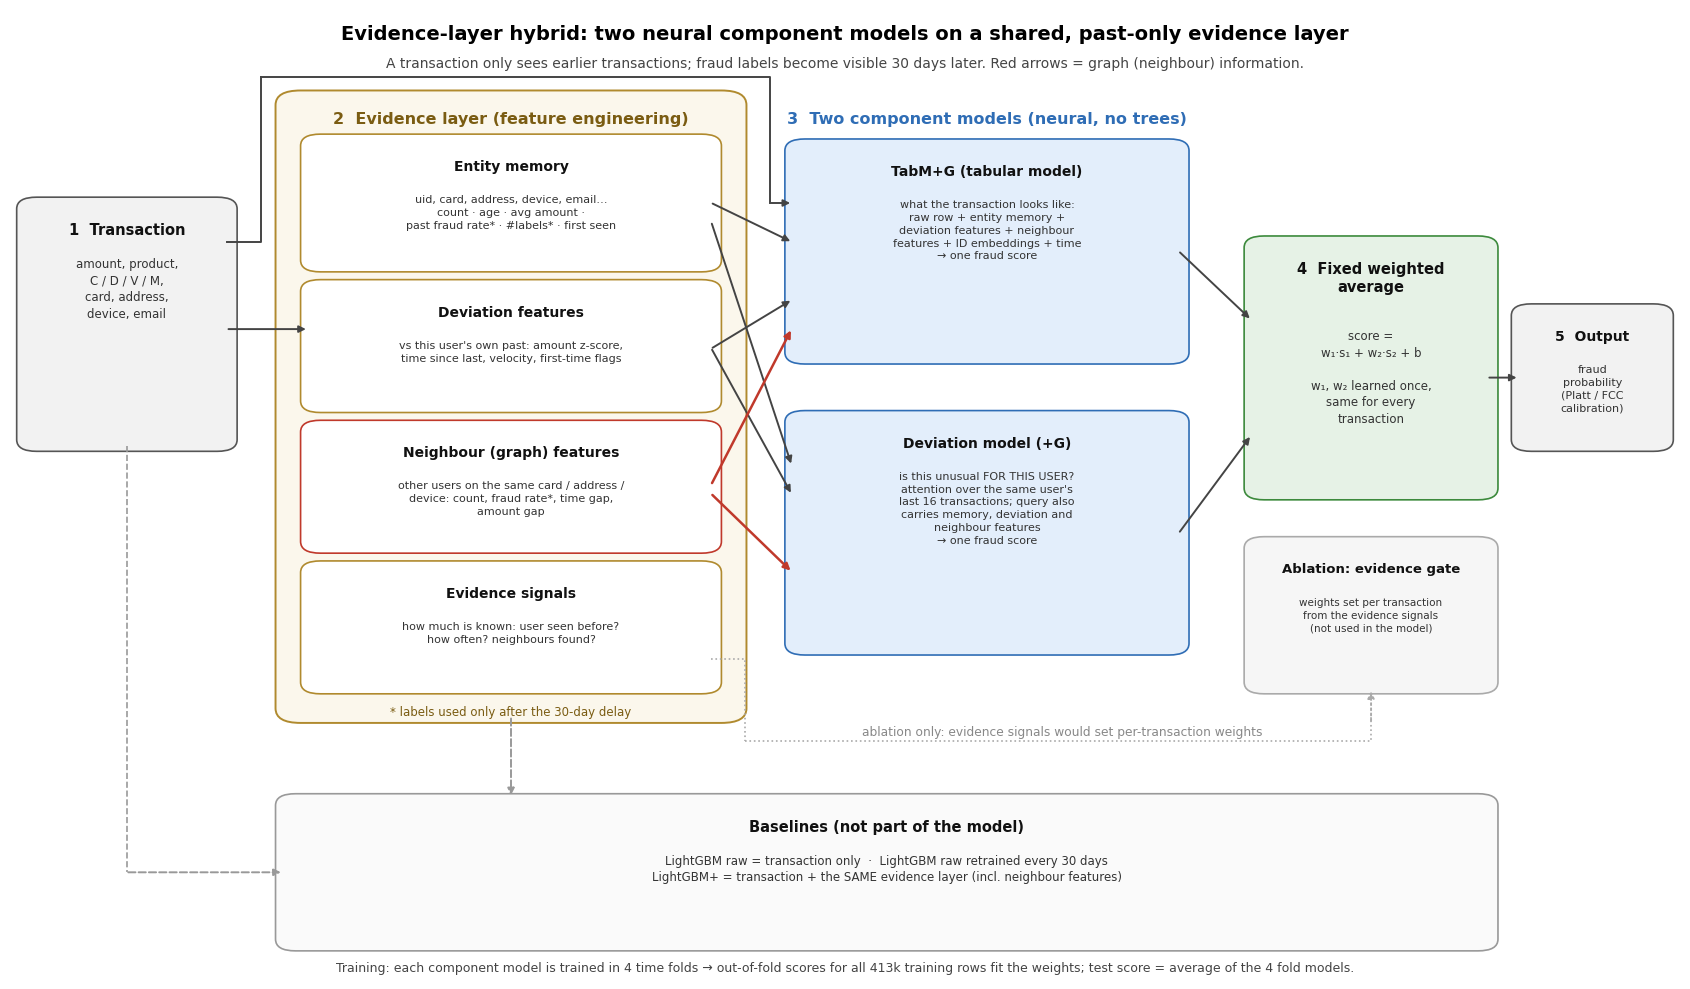

In [44]:
# ── 4 · Architecture diagram (no data needed; saved to the store folder) ──
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def box(ax, x, y, w, h, title, body='', fc='#f2f2f2', ec='#555555', fs=10.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.006,rounding_size=0.012', fc=fc, ec=ec, lw=1.2))
    ax.text(x + w / 2, y + h - 0.02, title, ha='center', va='top', fontsize=fs, weight='bold', color='#111111')
    if body: ax.text(x + w / 2, y + h - 0.056, body, ha='center', va='top', fontsize=fs - 2, color='#333333', linespacing=1.35)

def arrow(ax, x0, y0, x1, y1, c='#444444', ls='-', lw=1.4):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='-|>', color=c, lw=lw, ls=ls, shrinkA=1, shrinkB=1))

fig, ax = plt.subplots(figsize=(17, 10)); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
GOLD, GOLD_E, BLUE, BLUE_E, GREEN, GREEN_E, GRAPH = '#fbf7ec', '#b08a2e', '#e3eefb', '#2f6db5', '#e6f2e6', '#3c8a3c', '#c0392b'
ax.text(0.5, 0.985, 'Evidence-layer hybrid: two neural component models on a shared, past-only evidence layer', ha='center', va='top', fontsize=14, weight='bold')
ax.text(0.5, 0.952, 'A transaction only sees earlier transactions; fraud labels become visible 30 days later. '
        'Red arrows = graph (neighbour) information.', ha='center', va='top', fontsize=10, color='#444444')

box(ax, 0.01, 0.55, 0.12, 0.25, '1  Transaction', 'amount, product,\nC / D / V / M,\ncard, address,\ndevice, email', '#f2f2f2')

ax.add_patch(FancyBboxPatch((0.165, 0.27), 0.27, 0.64, boxstyle='round,pad=0.006,rounding_size=0.015', fc=GOLD, ec=GOLD_E, lw=1.4))
ax.text(0.30, 0.895, '2  Evidence layer (feature engineering)', ha='center', va='top', fontsize=11.5, weight='bold', color='#7a5c12')
box(ax, 0.18, 0.735, 0.24, 0.13, 'Entity memory', 'uid, card, address, device, email…\ncount · age · avg amount ·\npast fraud rate* · #labels* · first seen', 'white', GOLD_E, 10)
box(ax, 0.18, 0.59, 0.24, 0.125, 'Deviation features', "vs this user's own past: amount z-score,\ntime since last, velocity, first-time flags", 'white', GOLD_E, 10)
box(ax, 0.18, 0.445, 0.24, 0.125, 'Neighbour (graph) features', 'other users on the same card / address /\ndevice: count, fraud rate*, time gap,\namount gap', 'white', GRAPH, 10)
box(ax, 0.18, 0.30, 0.24, 0.125, 'Evidence signals', 'how much is known: user seen before?\nhow often? neighbours found?', 'white', GOLD_E, 10)
ax.text(0.30, 0.282, '* labels used only after the 30-day delay', ha='center', va='top', fontsize=8.5, color='#7a5c12')

ax.text(0.585, 0.895, '3  Two component models (neural, no trees)', ha='center', va='top', fontsize=11.5, weight='bold', color=BLUE_E)
box(ax, 0.47, 0.64, 0.23, 0.22, 'TabM+G (tabular model)', 'what the transaction looks like:\nraw row + entity memory +\ndeviation features + neighbour\nfeatures + ID embeddings + time\n→ one fraud score', BLUE, BLUE_E, 10)
box(ax, 0.47, 0.34, 0.23, 0.24, 'Deviation model (+G)', "is this unusual FOR THIS USER?\nattention over the same user's\nlast 16 transactions; query also\ncarries memory, deviation and\nneighbour features\n→ one fraud score", BLUE, BLUE_E, 10)

box(ax, 0.745, 0.50, 0.14, 0.26, '4  Fixed weighted\naverage', '\n\nscore =\nw₁·s₁ + w₂·s₂ + b\n\nw₁, w₂ learned once,\nsame for every\ntransaction', GREEN, GREEN_E, 10.5)
box(ax, 0.745, 0.30, 0.14, 0.15, 'Ablation: evidence gate', 'weights set per transaction\nfrom the evidence signals\n(not used in the model)', '#f6f6f6', '#aaaaaa', 9.5)
box(ax, 0.905, 0.55, 0.085, 0.14, '5  Output', 'fraud\nprobability\n(Platt / FCC\ncalibration)', '#f2f2f2', fs=10)

box(ax, 0.165, 0.035, 0.72, 0.15, 'Baselines (not part of the model)',
    'LightGBM raw = transaction only  ·  LightGBM raw retrained every 30 days\n'
    'LightGBM+ = transaction + the SAME evidence layer (incl. neighbour features)', '#fafafa', '#999999', 10.5)

arrow(ax, 0.13, 0.67, 0.178, 0.67)                                                     # transaction -> layer
ax.plot([0.13, 0.15, 0.15], [0.76, 0.76, 0.93], color='#444444', lw=1.4)              # raw row -> experts (top route)
ax.plot([0.15, 0.455, 0.455], [0.93, 0.93, 0.80], color='#444444', lw=1.4); arrow(ax, 0.455, 0.80, 0.468, 0.80)
arrow(ax, 0.42, 0.80, 0.468, 0.76); arrow(ax, 0.42, 0.78, 0.468, 0.53)                 # memory + deviation -> both experts
arrow(ax, 0.42, 0.65, 0.468, 0.70); arrow(ax, 0.42, 0.65, 0.468, 0.50)
arrow(ax, 0.42, 0.51, 0.468, 0.67, c=GRAPH, lw=1.8); arrow(ax, 0.42, 0.50, 0.468, 0.42, c=GRAPH, lw=1.8)   # graph -> both
for yy, ty in ((0.75, 0.68), (0.46, 0.56)): arrow(ax, 0.70, yy, 0.743, ty)              # component models -> average
ax.plot([0.42, 0.44, 0.44], [0.33, 0.33, 0.245], color='#aaaaaa', lw=1.2, ls=':')        # evidence signals -> gate (ablation only)
ax.plot([0.44, 0.815, 0.815], [0.245, 0.245, 0.27], color='#aaaaaa', lw=1.2, ls=':'); arrow(ax, 0.815, 0.265, 0.815, 0.298, c='#aaaaaa', ls=':')
ax.text(0.63, 0.252, 'ablation only: evidence signals would set per-transaction weights', ha='center', fontsize=8.8, color='#888888')
arrow(ax, 0.885, 0.62, 0.903, 0.62)
ax.plot([0.07, 0.07], [0.55, 0.11], color='#999999', lw=1.2, ls='--'); arrow(ax, 0.07, 0.11, 0.163, 0.11, c='#999999', ls='--')
arrow(ax, 0.30, 0.27, 0.30, 0.188, c='#999999', ls='--')
ax.text(0.5, 0.005, 'Training: each component model is trained in 4 time folds → out-of-fold scores for all 413k training rows fit the weights; '
        'test score = average of the 4 fold models.', ha='center', va='bottom', fontsize=9, color='#444444')
plt.tight_layout()
try: plt.savefig(P(STORE + 'architecture.png'), dpi=160, bbox_inches='tight')
except NameError: plt.savefig('architecture.png', dpi=160, bbox_inches='tight')
plt.show()

## Part 1 — Shared data (built once, then only loaded)
Cell 6 is the only dataset-specific loading code. Cells 7–12 build the tabular inputs, the past-only evidence layer and run the leak checks.

In [45]:
# ── 6 · Load, merge, NaN-safe uid, chronological split ──
if not have('base.parquet'):
    tr = reduce_mem(pd.read_csv(DATA_DIR + 'train_transaction.csv'))
    idn = reduce_mem(pd.read_csv(DATA_DIR + 'train_identity.csv'))
    df = reduce_mem(tr.merge(idn, on='TransactionID', how='left')); del tr, idn; gc.collect()
    df = df.sort_values('TransactionDT', kind='stable').reset_index(drop=True)
    df['D1n'] = (df.TransactionDT // 86400 - df.D1).astype(np.float32)          # day the card was first used
    s = lambda c: df[c].astype(str)
    old = s('card1') + '_' + s('addr1') + '_' + s('D1n')                          # v2 uid: NaN became the text 'nan'
    ok = df[['card1', 'addr1', 'D1n']].notna().all(axis=1).to_numpy()
    seen_v2 = old.groupby(old).cumcount().to_numpy()                             # earlier sightings under the v2 uid
    big = seen_v2 >= 101
    print(f'rows with an incomplete uid (merged through "nan" in v2, no uid in v3): {(~ok).mean():.1%}')
    print(f"v2 '101+' rows: {big.sum()}, of which NaN-merged: {(~ok[big]).mean() if big.any() else 0:.0%}")
    df['uid'] = old.where(ok).astype('category')                                  # v3: missing part -> no uid
    df['card_bundle'] = (s('card1') + '_' + s('card2') + '_' + s('card3') + '_' + s('card5') + '_' + s('card4') + '_' + s('card6')).where(df.card1.notna()).astype('category')
    del old, seen_v2, big
    n = len(df)   # 70% train | 7.5% early stopping | 7.5% calibration | 15% test
    df['split'] = np.searchsorted((np.array([.70, .775, .85]) * n).astype(int), np.arange(n), 'right').astype(np.int8)
    df.to_parquet(P('base.parquet')); del df; gc.collect()
print(pd.read_parquet(P('base.parquet'), columns=['split', 'isFraud']).groupby('split').isFraud.agg(['size', 'mean']))

         size      mean
split                  
0      413378  0.035169
1       44290  0.035967
2       44291  0.032715
3       88581  0.034804


In [46]:
# ── 7 · Tabular inputs: the transaction's own details (v4: card2/3/5, addr2, id_30, id_33 added back) ──
if not have('Xnum4.npy'):
    df = pd.read_parquet(P('base.parquet')); n, ntr = len(df), int((df.split == 0).sum())
    drop = set(ENT + ['D1n', 'TransactionID', 'isFraud', 'TransactionDT', 'split'])
    cat = [c for c in df.columns if c not in drop and str(df[c].dtype) == 'category']
    num = [c for c in df.columns if c not in drop and c not in cat]
    if not have('y.npy', 'split.npy', 't.npy', 'amt.npy', 'd1.npy'):
        np.save(P('y.npy'), df.isFraud.to_numpy(np.int8)); np.save(P('split.npy'), df.split.to_numpy())
        np.save(P('t.npy'), df.TransactionDT.to_numpy(np.int64)); np.save(P('amt.npy'), df.TransactionAmt.to_numpy(np.float32))
        np.save(P('d1.npy'), np.nan_to_num(np.log1p(df.D1.clip(lower=0).to_numpy(np.float32)), nan=-1))
    if not have('miss.npy'):   # share of missing values, over v3's numeric columns (kept identical so v3 caches stay valid)
        np.save(P('miss.npy'), df[[c for c in num if c not in EXTRA_TAB]].isna().mean(axis=1).to_numpy(np.float32))
    C, cards = np.zeros((n, len(cat)), np.int16), []
    for j, c in enumerate(cat):
        code = df[c].cat.codes.to_numpy().astype(np.int32) + 1                 # 0 = missing
        code[~(np.bincount(code[:ntr], minlength=code.max() + 1) > 0)[code]] = 0   # unseen in training -> missing
        C[:, j] = code; cards.append(int(code.max()) + 1)
    hour = ((df.TransactionDT.to_numpy() / 3600) % 24).astype(np.float32)
    X = df[num].to_numpy(np.float32, copy=True); del df; gc.collect()
    sgn = np.sign(X); np.abs(X, out=X); np.log1p(X, out=X); X *= sgn; del sgn          # signed log, in place
    X -= np.nanmean(X[:ntr], 0); X /= np.nanstd(X[:ntr], 0) + 1e-6                     # train statistics only
    np.clip(X, -8, 8, out=X); np.nan_to_num(X, copy=False)
    X = np.c_[X, np.sin(hour * np.pi / 12), np.cos(hour * np.pi / 12), np.load(P('miss.npy'))].astype(np.float16)
    json.dump(num + ['hour_sin', 'hour_cos', 'missing'], open(P('num_cols4.json'), 'w'))
    np.save(P('Xcat4.npy'), C); json.dump(cards, open(P('cards4.json'), 'w')); np.save(P('Xnum4.npy'), X)
    del X, C; gc.collect()
print('tabular expert inputs: numeric', np.load(P('Xnum4.npy'), mmap_mode='r').shape, '| categorical', np.load(P('Xcat4.npy'), mmap_mode='r').shape)

tabular expert inputs: numeric (590540, 401) | categorical (590540, 27)


In [47]:
# ── 8 · Past-only entity memory (depends on DELAY) ──
if not have(f'hist_{TAG}.npy'):
    df = pd.read_parquet(P('base.parquet'), columns=ENT)
    y, t, la = np.load(P('y.npy')), np.load(P('t.npy')), np.log1p(np.load(P('amt.npy'))) / 5
    ntr, n = int((np.load(P('split.npy')) == 0).sum()), len(y)
    H = np.zeros((n, len(ENT), 6), np.float16)
    for j, c in enumerate(ENT):
        g = pd.factorize(df[c])[0]
        h, cnt = entity_hist(g, t, y, la, DELAY, ntr, y[:ntr].mean()); H[:, j] = h
        if c == 'uid': np.save(P('cnt_uid.npy'), cnt); np.save(P('uid_missing.npy'), (g < 0).astype(np.float32))
    np.save(P(f'hist_{TAG}.npy'), H); del df, H; gc.collect()
cnt = np.load(P('cnt_uid.npy')); te = np.load(P('split.npy')) == 3
print('test rows per familiarity bin:', dict(zip(FAM, np.bincount(fam_bin(cnt[te]), minlength=5).tolist())),
      f"| test rows with no uid: {np.load(P('uid_missing.npy'))[te].mean():.1%} (counted in bin '0')")

test rows per familiarity bin: {'0': 33166, '1-5': 30387, '6-20': 18514, '21-100': 5023, '101+': 1491} | test rows with no uid: 10.5% (counted in bin '0')


In [48]:
# ── 9 · Relational indexes (no labels): uid sequences, cross-user neighbours, deviation features ──
need = not have('seq.npy', 'nb_recent.npy', f'nb_known_{TAG}.npy', 'dev.npy')
if need:
    base = pd.read_parquet(P('base.parquet'), columns=list(dict.fromkeys(['uid'] + GRAPH_ENT + DEV_NEW)))
    t, amt = np.load(P('t.npy')), np.load(P('amt.npy')); uid = pd.factorize(base.uid)[0]
    if not have('seq.npy'): np.save(P('seq.npy'), earlier_rows(uid, t, L_SEQ))
    G = {c: pd.factorize(base[c])[0] for c in GRAPH_ENT}
    if not have('nb_recent.npy'): np.save(P('nb_recent.npy'), np.stack([cross_user(G[c], uid, t, K) for c in GRAPH_ENT], 1))
    if not have(f'nb_known_{TAG}.npy'): np.save(P(f'nb_known_{TAG}.npy'), np.stack([cross_user(G[c], uid, t, K, DL) for c in GRAPH_ENT], 1))
    if not have('dev.npy'): np.save(P('dev.npy'), dev_features(uid, t, amt, {c: base[c] for c in DEV_NEW}))
    del base, G; gc.collect()
print('mean past uid transactions in sequence:', round(float((np.load(P('seq.npy'), mmap_mode='r') >= 0).sum(1).mean()), 2))
print('mean neighbours per relation', GRAPH_ENT, '| recent:', (np.load(P('nb_recent.npy'), mmap_mode='r') >= 0).sum(2).mean(0).round(2),
      '| label visible:', (np.load(P(f'nb_known_{TAG}.npy'), mmap_mode='r') >= 0).sum(2).mean(0).round(2))

mean past uid transactions in sequence: 2.88
mean neighbours per relation ['card1', 'addr1', 'DeviceInfo'] | recent: [7.27 7.09 1.52] | label visible: [5.62 5.47 0.84]


In [49]:
# ── 10 · Verification: past-only checks and the memory null test. Runs once; later sessions just print the stored result ──
y, t, la = np.load(P('y.npy')), np.load(P('t.npy')), np.log1p(np.load(P('amt.npy'))) / 5
split = np.load(P('split.npy')); ntr, n = int((split == 0).sum()), len(y)
if not have(f'checks_{TAG}.json'):
    base = pd.read_parquet(P('base.parquet'), columns=list(dict.fromkeys(['uid'] + DEV_NEW))); g = pd.factorize(base.uid)[0]
    fut = t > np.median(t); rng = np.random.default_rng(0); chk = {}           # scramble the future: the past must not change
    y2, la2 = y.copy(), la.copy(); y2[fut] = 1 - y2[fut]; la2[fut] = 0
    a, b = entity_hist(g, t, y, la, DELAY, ntr, .035)[0], entity_hist(g, t, y2, la2, DELAY, ntr, .035)[0]
    chk['entity memory past-only'] = bool(np.allclose(a[~fut], b[~fut]))
    amt2 = np.load(P('amt.npy')).copy(); amt2[fut] = rng.permutation(amt2[fut]); cats2 = {}
    for c in DEV_NEW: v = base[c].to_numpy(copy=True); v[fut] = rng.permutation(v[fut]); cats2[c] = pd.Series(v)
    chk['deviation features past-only'] = bool(np.allclose(np.load(P('dev.npy'))[~fut], dev_features(g, t, amt2, cats2)[~fut]))
    seq = np.load(P('seq.npy')); r = np.nonzero(seq >= 0); nbv = seq[r]
    chk['user sequences past-only, same user'] = bool((nbv < r[0]).all() and (g[nbv] == g[r[0]]).all())
    for f, strict in [('nb_recent.npy', False), (f'nb_known_{TAG}.npy', True)]:
        nb = np.load(P(f)); r = np.nonzero(nb >= 0); nbv = nb[r]
        chk[f'{f} past-only'] = bool((t[nbv] < t[r[0]] - DL).all() if strict else (nbv < r[0]).all())
        chk[f'{f} other users only'] = bool((~((g[nbv] == g[r[0]]) & (g[r[0]] >= 0))).all())
    json.dump(chk, open(P(f'checks_{TAG}.json'), 'w')); del a, b, seq, nb, r, nbv, base; gc.collect()
for k, v in json.load(open(P(f'checks_{TAG}.json'))).items(): print(f'{k}: {"PASS" if v else "FAIL"}')

# Null test v3. Shuffle ALL labels once (train and test alike), rebuild the entity memory from the shuffled labels,
# train LightGBM+ on shuffled training labels and score against the SAME shuffled test labels. Without a leak no
# feature can know a row's own shuffled label -> ROC-AUC ~ 0.50. A memory that reads its own label scores well above.
if not have(f'null_test_{TAG}.json'):
    ents = pd.read_parquet(P('base.parquet'), columns=ENT); Gs = [pd.factorize(ents[c])[0] for c in ENT]; del ents
    X = lgb_X(); hc = [f'm{i}' for i in range(len(ENT) * 6)]; tr, te = split == 0, split == 3; res = []
    for s_ in range(3):
        yp = np.random.default_rng(100 + s_).permutation(y)
        X[hc] = np.stack([entity_hist(gg, t, yp, la, DELAY, ntr, yp[:ntr].mean())[0] for gg in Gs], 1).reshape(n, -1)
        m = lgb.train(dict(objective='binary', learning_rate=.1, num_leaves=64, seed=s_, verbose=-1), lgb.Dataset(X[tr], yp[tr]), 200)
        p = m.predict(X[te]); res.append(dict(shuffled=round(auc(yp[te], p), 4), real=round(auc(y[te], p), 4))); print('shuffle', s_, res[-1])
    json.dump(res, open(P(f'null_test_{TAG}.json'), 'w')); del X, m; gc.collect()
res = json.load(open(P(f'null_test_{TAG}.json'))); mu = np.mean([r['shuffled'] for r in res])
n1 = int(y[split == 3].sum()); n0 = int((split == 3).sum()) - n1
tol = 3 * math.sqrt((n0 + n1 + 1) / (12 * n0 * n1)) / math.sqrt(len(res))     # 3 standard errors of a chance AUC
verdict = ('PASS: no label leak through the memory' if abs(mu - .5) <= tol else
           'LEAK SUSPECTED: a feature knows its own (shuffled) label' if mu > .5 else 'below chance: check the evaluation, not a leak')
print(f'null test, ROC-AUC vs shuffled labels: {[r["shuffled"] for r in res]} -> mean {mu:.3f} (chance band 0.5 ± {tol:.3f}): {verdict}')
print('(vs real labels, for reference only -- a model trained on noise can rank real fraud below 0.5; that is not a leak):', [r['real'] for r in res])

entity memory past-only: PASS
deviation features past-only: PASS
user sequences past-only, same user: PASS
nb_recent.npy past-only: PASS
nb_recent.npy other users only: PASS
nb_known_d30.npy past-only: PASS
nb_known_d30.npy other users only: PASS
null test, ROC-AUC vs shuffled labels: [0.5054, 0.5036, 0.493] -> mean 0.501 (chance band 0.5 ± 0.009): PASS: no label leak through the memory
(vs real labels, for reference only -- a model trained on noise can rank real fraud below 0.5; that is not a leak): [0.5073, 0.4509, 0.455]


In [50]:
# ── 11 · TabM+ inputs (built once, no labels): everything LightGBM+ sees + ID embeddings + frequency + time embeddings ──
if not have('Xplus_num.npy', 'Xplus_cat.npy'):
    y, split = np.load(P('y.npy')), np.load(P('split.npy')); n, ntr = len(y), int((split == 0).sum())
    base = pd.read_parquet(P('base.parquet'), columns=list(dict.fromkeys(HC_FREQ + HC_CAT + ['TransactionDT'])))
    Fq = []
    for c in HC_FREQ:            # how common is this ID value in the training period (frequency encoding)
        code = pd.factorize(base[c])[0]; tc = code[:ntr]; cnt = np.bincount(tc[tc >= 0], minlength=code.max() + 1)
        Fq.append(np.where(code >= 0, np.log1p(cnt[np.maximum(code, 0)]), -1).astype(np.float32))
    Fq = np.stack(Fq, 1); Fq = (Fq - Fq[:ntr].mean(0)) / (Fq[:ntr].std(0) + 1e-6)
    day = base.TransactionDT.to_numpy() / 86400                               # Fourier time embedding (Cai & Ye, ICML 2025)
    Te = np.c_[np.sin(2 * np.pi * day / 7), np.cos(2 * np.pi * day / 7), np.sin(2 * np.pi * day / 30.4), np.cos(2 * np.pi * day / 30.4),
               (day - day[:ntr].mean()) / day[:ntr].std()].astype(np.float32)
    M = np.c_[np.load(P(f'hist_{TAG}.npy')).astype(np.float32).reshape(n, -1), evidence(), np.load(P('dev.npy'))]
    np.save(P('Xplus_num.npy'), np.c_[np.load(P('Xnum4.npy')).astype(np.float32), M, Fq, Te].astype(np.float16))
    Cc, cards = [], json.load(open(P('cards4.json')))
    for c in HC_CAT:             # ID embeddings: values seen >= MIN_CAT times in training get their own vector
        code = pd.factorize(base[c])[0]; tc = code[:ntr]; cnt = np.bincount(tc[tc >= 0], minlength=code.max() + 1)
        keep = np.where(cnt >= MIN_CAT)[0]; mp = np.zeros(code.max() + 2, np.int32); mp[keep + 1] = np.arange(1, len(keep) + 1)
        Cc.append(mp[code + 1]); cards.append(len(keep) + 1)
    np.save(P('Xplus_cat.npy'), np.c_[np.load(P('Xcat4.npy')), np.stack(Cc, 1)].astype(np.int32)); json.dump(cards, open(P('cards_plus.json'), 'w'))
    del base, M, Fq; gc.collect()
print('TabM+ inputs: numeric', np.load(P('Xplus_num.npy'), mmap_mode='r').shape, '| categorical', np.load(P('Xplus_cat.npy'), mmap_mode='r').shape,
      '| ID vocabulary sizes', json.load(open(P('cards_plus.json')))[-len(HC_CAT):])

TabM+ inputs: numeric (590540, 490) | categorical (590540, 36) | ID vocabulary sizes [1435, 491, 50, 76, 58, 46, 168, 79, 1476]


In [51]:
# ── 12 · Neighbour (graph) features: built once; labels enter only through the delay ──
if not have(f'nbf_{TAG}.npy'):
    y, t, amt = np.load(P('y.npy')).astype(np.float32), np.load(P('t.npy')), np.load(P('amt.npy'))
    split = np.load(P('split.npy')); ntr = int((split == 0).sum())
    nr, nk = np.load(P('nb_recent.npy')), np.load(P(f'nb_known_{TAG}.npy'))
    NBF = nb_features(y, t, amt, nr, nk, y[:ntr].mean())
    fut = t > np.median(t); y2 = y.copy(); y2[fut] = 1 - y2[fut]              # past-only check: flip future labels
    ok = np.allclose(NBF[~fut], nb_features(y2, t, amt, nr, nk, y[:ntr].mean())[~fut])
    print('neighbour features past-only:', 'PASS' if ok else 'FAIL'); assert ok
    NBF = (NBF - NBF[:ntr].mean(0)) / (NBF[:ntr].std(0) + 1e-6)
    np.save(P(f'nbf_{TAG}.npy'), NBF.astype(np.float32)); del nr, nk, NBF; gc.collect()
print('neighbour features:', np.load(P(f'nbf_{TAG}.npy'), mmap_mode='r').shape, '(3 relations x 5)')

neighbour features: (590540, 15) (3 relations x 5)


## Part 2 — Models for `SEED`
LightGBM first (no GPU), then the two component models, the ablation models and the combiners. Each cell prints test PR-AUC and ROC-AUC as it finishes.

In [52]:
# ── 14 · LightGBM for SEED: the three baselines (+ evidence-layer ablations) ──
y, split, *_ = common(); mf = model_files(); tr, va = split == 0, split == 1
JOBS = {'lgb_raw': dict(mem=False, dev=False),              # transaction only
        'lgb_g': dict(nbf=True)}                            # LightGBM+ = transaction + the full evidence layer (same information as the hybrid)
if RUN_ABLATIONS:
    JOBS.update({'lgb_plus': dict(),                        # evidence layer without neighbour features
                 'lgb_mem': dict(dev=False),                # + entity memory only
                 'lgb_dev': dict(mem=False),                # + deviation features only
                 'lgb_nolabel': dict(label_free=True)})     # + evidence layer WITHOUT any fraud labels
for key, kw in JOBS.items():
    if not has_score(key): X = lgb_X(**kw); run_lgb(mf[key], X, y, tr, va); del X; gc.collect()
run_lgb_retrained(mf['lgb_rt'])                             # transaction only, retrained every RT_DAYS on visible labels
print('LightGBM done for seed', SEED)

LightGBM done for seed 123


In [53]:
# ── 15 · Label-delay sweep: LightGBM+ (without neighbour features) at 0 / 7 / 60 days. Runs on the first seed only ──
if RUN_DELAY_SWEEP:
    y, split, *_ = common(); tr, va = split == 0, split == 1; t = np.load(P('t.npy'))
    la = np.log1p(np.load(P('amt.npy'))) / 5; ntr = int(tr.sum())
    for d in SWEEP_DELAYS:
        tg = f'd{d}'; key = f'lgb_plus_d{d}'
        if has_score(key): continue
        if not have(f'hist_{tg}.npy'):
            ents = pd.read_parquet(P('base.parquet'), columns=ENT); H = np.zeros((len(y), len(ENT), 6), np.float16)
            for j, c in enumerate(ENT): H[:, j] = entity_hist(pd.factorize(ents[c])[0], t, y, la, d, ntr, y[:ntr].mean())[0]
            np.save(P(f'hist_{tg}.npy'), H); del ents, H
        if not have(f'nb_known_{tg}.npy'):
            base = pd.read_parquet(P('base.parquet'), columns=['uid'] + GRAPH_ENT); uid = pd.factorize(base.uid)[0]
            np.save(P(f'nb_known_{tg}.npy'), np.stack([cross_user(pd.factorize(base[c])[0], uid, t, K, d * 86400) for c in GRAPH_ENT], 1)); del base
        X = lgb_X(tag=tg); run_lgb(model_files()[key], X, y, tr, va); del X; gc.collect()
    print('delay sweep done')
else: print(f'delay sweep runs on seed {SEEDS_PLAN[0]} only -- skipped for seed {SEED}')

delay sweep runs on seed 42 only -- skipped for seed 123


In [54]:
# ── 16 · The two component models, both with the neighbour (graph) features ──
NBF = np.load(P(f'nbf_{TAG}.npy'))
run_tabular(EXPERT_STEM['tabpg'], 'tabm', extra=NBF, edges_file='ple_edges_plusg.npy'); print('TabM+G done for seed', SEED)
run_dev(EXPERT_STEM['devg'], extra=NBF); print('deviation model (+G) done for seed', SEED)
del NBF

TabM+G done for seed 123
deviation model (+G) done for seed 123


In [55]:
# ── 17 · Ablation models (for the analysis tables): no-graph TabM+ and deviation model, graph model, TabNet ──
if RUN_ABLATIONS:
    run_tabular(EXPERT_STEM['tabp'], 'tabm'); print('TabM+ (no graph features) done')
    run_dev(EXPERT_STEM['dev']); print('deviation model (no graph features) done')
    run_gnn(EXPERT_STEM['gnn']); print('graph model done')
    run_tabular(EXPERT_STEM['tabnet'], 'tabnet'); print('TabNet done')
else: print('ablations switched off (RUN_ABLATIONS = False)')

TabM+ (no graph features) done
deviation model (no graph features) done
graph model done
TabNet done


In [56]:
# ── 18 · Combiners for SEED: the fixed weighted average (the model) + ablations, fitted on the out-of-fold scores of all 413k training rows ──
y, split, yg, idx = common(); n = len(y); sd = SEED; gtr, gva, ALL = idx[0], idx[1], torch.arange(n, device=DEV)
EV = torch.tensor(evidence(), device=DEV); mf = model_files()
stop_pr = json.load(open(P(f'stop_pr_{XT}_s{sd}.json'))) if have(f'stop_pr_{XT}_s{sd}.json') else {}
for key, (kind, ex) in COMBOS.items():
    f = f'score_{mf[key]}_s{sd}.npy'
    if have(f): continue
    if not all(has_score(e) for e in ex): print(f'skip {key}: component model(s) not trained', [e for e in ex if not has_score(e)]); continue
    L = torch.tensor(np.stack([score(e) for e in ex], 1), device=DEV); torch.manual_seed(sd)
    g = Gate(0 if kind == 'fixed' else EV.shape[1], len(ex)).to(DEV)
    bf = (lambda b: (EV[b, :0], L[b])) if kind == 'fixed' else (lambda b: (EV[b], L[b]))
    best = fit(g, bf, gtr, gva, yg, epochs=60, bs=4096, lr=3e-3, patience=6); o = predict(g, bf, ALL)
    np.save(P(f), o[0]); np.save(P(f'w_{mf[key]}_s{sd}.npy'), o[1].astype(np.float16))
    stop_pr[key] = float(best); json.dump(stop_pr, open(P(f'stop_pr_{XT}_s{sd}.json'), 'w'))
    print(f'{key:11s} ({kind}, {"+".join(ex)}): stop PR-AUC {best:.4f}'); del g, L
del EV; torch.cuda.empty_cache(); print('combiners done for seed', SEED)

  epoch 0  stop PR-AUC 0.7500
  epoch 1  stop PR-AUC 0.7500
  epoch 2  stop PR-AUC 0.7504
  epoch 3  stop PR-AUC 0.7502
  epoch 4  stop PR-AUC 0.7505
  epoch 5  stop PR-AUC 0.7503
  epoch 6  stop PR-AUC 0.7505
  epoch 7  stop PR-AUC 0.7503
  epoch 8  stop PR-AUC 0.7504
  epoch 9  stop PR-AUC 0.7505
  epoch 10  stop PR-AUC 0.7504
hyb         (fixed, tabpg+devg): stop PR-AUC 0.7505
  epoch 0  stop PR-AUC 0.7502
  epoch 1  stop PR-AUC 0.7524
  epoch 2  stop PR-AUC 0.7526
  epoch 3  stop PR-AUC 0.7531
  epoch 4  stop PR-AUC 0.7530
  epoch 5  stop PR-AUC 0.7524
  epoch 6  stop PR-AUC 0.7537
  epoch 7  stop PR-AUC 0.7531
  epoch 8  stop PR-AUC 0.7536
  epoch 9  stop PR-AUC 0.7525
  epoch 10  stop PR-AUC 0.7530
  epoch 11  stop PR-AUC 0.7527
  epoch 12  stop PR-AUC 0.7524
hyb_gate    (evid, tabpg+devg): stop PR-AUC 0.7537
  epoch 0  stop PR-AUC 0.7468
  epoch 1  stop PR-AUC 0.7470
  epoch 2  stop PR-AUC 0.7474
  epoch 3  stop PR-AUC 0.7470
  epoch 4  stop PR-AUC 0.7475
  epoch 5  stop PR-AUC 

In [57]:
# ── 19 · Evaluate SEED and STORE the results (store_final/seed_<SEED>_*.csv). Re-running overwrites this seed only ──
y, split, *_ = common(); te, ca = split == 3, split == 2; yt = y[te]; mf = model_files(); sd = SEED
cnt = np.load(P('cnt_uid.npy')); fb = fam_bin(cnt)[te]
GROUP = np.select([fb == 0, fb == 1], ['new', 'few'], 'regular')       # new: 0 earlier transactions | few: 1-5 | regular: 6+
S = {k: np.load(P(f'score_{v}_s{sd}.npy')) for k, v in mf.items() if have(f'score_{v}_s{sd}.npy')}
print(f'seed {sd}: {len(S)} score sets found:', list(S))

rows = []
for k, s in S.items():
    p = s[te]; r = dict(seed=sd, model=k, pr=ap(yt, p), roc=auc(yt, p), recall_1pct=recall_at(yt, p, .01))
    for g in ['new', 'few', 'regular']: m = GROUP == g; r[f'pr_{g}'], r[f'roc_{g}'] = ap(yt[m], p[m]), auc(yt[m], p[m])
    tf = f'time_{mf[k]}_s{sd}.json'; r['train_min'] = json.load(open(P(tf)))['sec'] / 60 if have(tf) else np.nan
    rows.append(r)
pd.DataFrame(rows).to_csv(P(STORE + f'seed_{sd}_metrics.csv'), index=False)

COMPARE = [   # (section, question, model A, model B, user group): difference = A - B
    ('Main', 'Hybrid vs LightGBM raw', 'hyb', 'lgb_raw', 'all'),
    ('Main', 'Hybrid vs LightGBM raw retrained every 30 days', 'hyb', 'lgb_rt', 'all'),
    ('Main', 'Hybrid vs LightGBM+', 'hyb', 'lgb_g', 'all'),
    ('Main', 'Hybrid vs LightGBM+ -- new users', 'hyb', 'lgb_g', 'new'),
    ('Main', 'Hybrid vs LightGBM+ -- few-history users', 'hyb', 'lgb_g', 'few'),
    ('Main', 'Hybrid vs LightGBM+ -- regular users', 'hyb', 'lgb_g', 'regular'),
    ('Information', 'LightGBM+ vs LightGBM raw', 'lgb_g', 'lgb_raw', 'all'),
    ('Information', 'LightGBM+ vs LightGBM raw retrained every 30 days', 'lgb_g', 'lgb_rt', 'all'),
    ('Information', 'LightGBM raw: retrained every 30 days vs trained once', 'lgb_rt', 'lgb_raw', 'all'),
    ('Information', 'Entity memory only vs LightGBM raw', 'lgb_mem', 'lgb_raw', 'all'),
    ('Information', 'Deviation features only vs LightGBM raw', 'lgb_dev', 'lgb_raw', 'all'),
    ('Information', 'Evidence layer without labels vs LightGBM raw', 'lgb_nolabel', 'lgb_raw', 'all'),
    ('Information', 'Neighbour features added to LightGBM+', 'lgb_g', 'lgb_plus', 'all'),
    ('TabNet', 'TabNet vs TabM+ (same inputs)', 'tabnet', 'tabp', 'all'),
    ('TabNet', 'Hybrid with TabNet vs hybrid with TabM+', 'hyb_tabnet', 'hyb_nog', 'all'),
    ('Graph', 'Graph model added to the hybrid (no graph features)', 'hyb_gexp', 'hyb_nog', 'all'),
    ('Graph', 'Graph as features (2 models) vs graph as a third model', 'hyb', 'hyb_gexp', 'all'),
    ('Graph', 'Graph features in both models vs no graph information', 'hyb', 'hyb_nog', 'all'),
    ('Graph', 'Graph features in TabM only vs in both models', 'hyb_tg', 'hyb', 'all'),
    ('Graph', 'Graph model added on top of graph features', 'hyb_both', 'hyb', 'all'),
    ('Graph', 'Graph features added to TabM+', 'tabpg', 'tabp', 'all'),
    ('Graph', 'Graph features added to the deviation model', 'devg', 'dev', 'all'),
    ('Graph', 'Graph features added to the deviation model -- few-history users', 'devg', 'dev', 'few'),
    ('Graph', 'Graph features added to the deviation model -- regular users', 'devg', 'dev', 'regular'),
    ('Gate', 'Evidence gate vs fixed weighted average', 'hyb_gate', 'hyb', 'all'),
    ('Gate', 'Evidence gate vs fixed weighted average -- new users', 'hyb_gate', 'hyb', 'new'),
    ('Gate', 'Evidence gate vs fixed weighted average -- regular users', 'hyb_gate', 'hyb', 'regular')]
rng = np.random.default_rng(sd); B = [rng.integers(0, len(yt), len(yt)) for _ in range(200)]; Q = []
for sec, text, a, b, g in COMPARE:
    if a not in S or b not in S: continue
    m = np.ones(len(yt), bool) if g == 'all' else GROUP == g
    dpr, droc = [], []
    for i in B:
        j = i if g == 'all' else i[m[i]]
        dpr.append(ap(yt[j], S[a][te][j]) - ap(yt[j], S[b][te][j])); droc.append(auc(yt[j], S[a][te][j]) - auc(yt[j], S[b][te][j]))
    A, Bs = S[a][te][m], S[b][te][m]
    Q.append(dict(seed=sd, section=sec, question=text, a=a, b=b, group=g, d_pr=ap(yt[m], A) - ap(yt[m], Bs),
                  pr_lo=np.percentile(dpr, 2.5), pr_hi=np.percentile(dpr, 97.5), d_roc=auc(yt[m], A) - auc(yt[m], Bs),
                  roc_lo=np.percentile(droc, 2.5), roc_hi=np.percentile(droc, 97.5)))
pd.DataFrame(Q).to_csv(P(STORE + f'seed_{sd}_questions.csv'), index=False)

W = []                                                                 # mean weights on test rows, by user group
for key in ['hyb', 'hyb_gate']:
    f = f'w_{mf[key]}_s{sd}.npy'
    if not have(f): continue
    d = pd.DataFrame(np.load(P(f))[te].astype(np.float32), columns=COMBOS[key][1]); d['group'] = GROUP
    d = d.groupby('group').mean().reindex(['new', 'few', 'regular']).reset_index(); d['combiner'] = key; d['seed'] = sd; W.append(d)
if W: pd.concat(W).to_csv(P(STORE + f'seed_{sd}_gate.csv'), index=False)

C = []                                                                 # calibration (ECE) of the hybrid and LightGBM+
lf, d1 = np.log1p(cnt), np.load(P('d1.npy'))
for k in ['hyb', 'lgb_g']:
    if k not in S: continue
    s = S[k].astype(np.float64); Z = np.c_[s, lf, d1, s * lf, s * d1]
    for meth, p in {'raw': sig(s[te]), 'Platt': LR(C=100).fit(s[ca, None], y[ca]).predict_proba(s[te, None])[:, 1],
                    'FCC': LR(C=100, max_iter=1000).fit(Z[ca], y[ca]).predict_proba(Z[te])[:, 1]}.items():
        C.append(dict(seed=sd, model=k, method=meth, ece=ece(yt, p)))
pd.DataFrame(C).to_csv(P(STORE + f'seed_{sd}_calibration.csv'), index=False)
print(f'stored seed {sd} -> {WORK}{STORE}. Seeds stored so far:',
      sorted(int(f.split('_')[-2]) for f in glob.glob(P(STORE + 'seed_*_metrics.csv'))), '-- now run cell 21 (report).')

seed 123: 20 score sets found: ['lgb_raw', 'lgb_rt', 'lgb_g', 'lgb_plus', 'lgb_mem', 'lgb_dev', 'lgb_nolabel', 'tabpg', 'devg', 'tabp', 'dev', 'gnn', 'tabnet', 'hyb', 'hyb_gate', 'hyb_tg', 'hyb_nog', 'hyb_gexp', 'hyb_both', 'hyb_tabnet']
stored seed 123 -> /content/drive/MyDrive/CIS FRAUD DETECTION/egh_v3/store_final/. Seeds stored so far: [7, 42, 123] -- now run cell 21 (report).


## Part 3 — Results
PR-AUC is the main metric (fraud is 3.5% of transactions); ROC-AUC is reported next to it. **BETTER / WORSE** = the 95% paired-bootstrap interval of the PR-AUC difference excludes zero on every stored seed; otherwise **tie**.

In [58]:
# ── 21 · REPORT: reads every stored seed. Needs only cell 1 -- no GPU, no training ──
load = lambda kind: pd.concat([pd.read_csv(f) for f in sorted(glob.glob(P(STORE + f'seed_*_{kind}.csv')))]) \
    if glob.glob(P(STORE + f'seed_*_{kind}.csv')) else pd.DataFrame()
M, Qs, G, Cal = load('metrics'), load('questions'), load('gate'), load('calibration')
assert not M.empty, 'nothing stored yet -- run cells 14-19 for one seed first'
seeds = sorted(int(x) for x in M.seed.unique()); ns = len(seeds)
NAME = {'lgb_raw': 'LightGBM, raw features', 'lgb_rt': f'LightGBM, raw features, retrained every {RT_DAYS} days', 'lgb_g': 'LightGBM+ (raw + evidence layer)',
        'tabpg': 'TabM+G alone', 'devg': 'Deviation model (+G) alone', 'hyb': 'HYBRID (TabM+G + deviation +G, fixed weighted average)',
        'hyb_gate': 'Hybrid, evidence gate (ablation)', 'hyb_tg': 'Hybrid, graph features in TabM only', 'lgb_plus': 'LightGBM+ without neighbour features',
        'lgb_mem': 'LightGBM raw + entity memory only', 'lgb_dev': 'LightGBM raw + deviation features only', 'lgb_nolabel': 'LightGBM raw + evidence layer without labels',
        'tabp': 'TabM+ (no graph features)', 'dev': 'Deviation model (no graph features)', 'tabnet': 'TabNet (same inputs as TabM+)',
        'gnn': 'Graph model alone', 'hyb_nog': 'Hybrid, no graph information', 'hyb_gexp': 'Hybrid, graph as a third model',
        'hyb_both': 'Hybrid, graph as features + model', 'hyb_tabnet': 'Hybrid with TabNet (no graph)'}
NAME.update({f'lgb_plus_d{d}': f'LightGBM+ (no neighbours), label delay {d} days' for d in SWEEP_DELAYS})
pm = lambda m, s: f'{m:.4f}' if ns == 1 or pd.isna(s) else f'{m:.4f} ± {s:.4f}'
A = M.groupby('model').agg(pr=('pr', 'mean'), pr_sd=('pr', 'std'), roc=('roc', 'mean'), roc_sd=('roc', 'std'), rec=('recall_1pct', 'mean'),
                          new=('pr_new', 'mean'), few=('pr_few', 'mean'), regular=('pr_regular', 'mean'), mins=('train_min', 'mean'))

def table(keys, extra_cols=()):
    ks = [k for k in keys if k in A.index]
    t = pd.DataFrame({'PR-AUC': [pm(A.pr[k], A.pr_sd[k]) for k in ks], 'ROC-AUC': [pm(A.roc[k], A.roc_sd[k]) for k in ks]},
                     index=pd.Index([NAME.get(k, k) for k in ks], name='model'))
    for c, lab in extra_cols: t[lab] = [round(A[c][k], 4) if c != 'mins' else round(A[c][k], 1) for k in ks]
    return t

def verdict(q):   # BETTER / WORSE only if the PR-AUC 95% interval excludes 0 on EVERY stored seed
    v = ['BETTER' if lo > 0 else 'WORSE' if hi < 0 else 'tie' for lo, hi in zip(q.pr_lo, q.pr_hi)]
    return v[0] if len(set(v)) == 1 else 'mixed'

def section(sec):
    q = Qs[Qs.section == sec]
    if q.empty: return
    rows = [{'A vs B': t, 'Δ PR-AUC': f'{d.d_pr.mean():+.4f}', '95% CI (mean over seeds)': f'[{d.pr_lo.mean():+.4f}, {d.pr_hi.mean():+.4f}]',
             'Δ ROC-AUC': f'{d.d_roc.mean():+.4f}', 'verdict': verdict(d)} for t, d in q.groupby('question', sort=False)]
    display(pd.DataFrame(rows).set_index('A vs B'))

line = '─' * 110; yy, sp = np.load(P('y.npy')), np.load(P('split.npy'))
print(f'{line}\nRESULTS -- test set ({int((sp == 3).sum()):,} transactions, {yy[sp == 3].mean():.1%} fraud) -- seeds {seeds}' +
      (f'   [{ns} of {len(SEEDS_PLAN)} seeds: provisional]' if ns < len(SEEDS_PLAN) else '') + f'\n{line}')
print('BETTER / WORSE = the 95% bootstrap interval of the PR-AUC difference excludes 0 on every seed; otherwise tie.\n')
print('1) MAIN RESULT'); display(table(['lgb_raw', 'lgb_rt', 'lgb_g', 'tabpg', 'devg', 'hyb'], [('rec', 'recall @ 1% flagged')]))
print('   PR-AUC by how well the user is known (new = 0 earlier transactions, few = 1-5, regular = 6+)')
display(table(['lgb_raw', 'lgb_rt', 'lgb_g', 'tabpg', 'devg', 'hyb'], [('new', 'new'), ('few', 'few'), ('regular', 'regular')]).drop(columns=['PR-AUC', 'ROC-AUC']))
section('Main')
print(f'\n{line}\n2) THE INFORMATION SYSTEM: what the evidence layer adds to LightGBM')
display(table(['lgb_raw', 'lgb_rt', 'lgb_dev', 'lgb_nolabel', 'lgb_mem', 'lgb_plus', 'lgb_g'])); section('Information')
dl = [k for k in [f'lgb_plus_d{d}' for d in sorted(SWEEP_DELAYS + [DELAY])] if k in A.index or k == f'lgb_plus_d{DELAY}']
if any(k in A.index for k in dl):
    print('   Label delay (LightGBM+ without neighbour features; 30 days = the main setting)')
    rows = [(f'{d} days', A.pr['lgb_plus' if d == DELAY else f'lgb_plus_d{d}'], A.roc['lgb_plus' if d == DELAY else f'lgb_plus_d{d}'])
            for d in sorted(SWEEP_DELAYS + [DELAY]) if ('lgb_plus' if d == DELAY else f'lgb_plus_d{d}') in A.index]
    display(pd.DataFrame(rows, columns=['label delay', 'PR-AUC', 'ROC-AUC']).set_index('label delay').round(4))
print(f'\n{line}\n3) TabNet vs TabM'); display(table(['tabnet', 'tabp', 'hyb_tabnet', 'hyb_nog'], [('mins', 'train minutes (4 folds)')])); section('TabNet')
print(f'\n{line}\n4) GRAPH: as a model or as features'); display(table(['gnn', 'tabp', 'tabpg', 'dev', 'devg', 'hyb_nog', 'hyb_gexp', 'hyb_tg', 'hyb', 'hyb_both'],
                                                                     [('new', 'PR new'), ('regular', 'PR regular')])); section('Graph')
print(f'\n{line}\n5) GATE (ablation)'); display(table(['hyb', 'hyb_gate'])); section('Gate')
if not G.empty:
    print('   Mean weight on test rows'); display(G.groupby(['combiner', 'group'], sort=False)[['tabpg', 'devg']].mean().round(3))
if not Cal.empty:
    print(f'\n{line}\n6) CALIBRATION -- ECE, lower is better'); display(Cal.groupby(['model', 'method']).ece.mean().unstack().round(4).rename(index=NAME))

──────────────────────────────────────────────────────────────────────────────────────────────────────────────
RESULTS -- test set (88,581 transactions, 3.5% fraud) -- seeds [7, 42, 123]
──────────────────────────────────────────────────────────────────────────────────────────────────────────────
BETTER / WORSE = the 95% bootstrap interval of the PR-AUC difference excludes 0 on every seed; otherwise tie.

1) MAIN RESULT


,PR-AUC,ROC-AUC,recall @ 1% flagged
model,,,
"LightGBM, raw features",0.5459 ± 0.0026,0.9041 ± 0.0017,0.2568
"LightGBM, raw features, retrained every 30 days",0.5203 ± 0.0071,0.8949 ± 0.0017,0.2556
LightGBM+ (raw + evidence layer),0.6354 ± 0.0089,0.9344 ± 0.0013,0.2703
TabM+G alone,0.6047 ± 0.0043,0.9300 ± 0.0021,0.2632
Deviation model (+G) alone,0.5948 ± 0.0020,0.9282 ± 0.0010,0.2664
"HYBRID (TabM+G + deviation +G, fixed weighted average)",0.6296 ± 0.0013,0.9364 ± 0.0006,0.2681


   PR-AUC by how well the user is known (new = 0 earlier transactions, few = 1-5, regular = 6+)


,new,few,regular
model,,,
"LightGBM, raw features",0.7002,0.2821,0.3174
"LightGBM, raw features, retrained every 30 days",0.6877,0.2504,0.2348
LightGBM+ (raw + evidence layer),0.6969,0.3924,0.7521
TabM+G alone,0.6624,0.3462,0.7375
Deviation model (+G) alone,0.6510,0.3329,0.7477
"HYBRID (TabM+G + deviation +G, fixed weighted average)",0.6818,0.3745,0.7750


,Δ PR-AUC,95% CI (mean over seeds),Δ ROC-AUC,verdict
A vs B,,,,
Hybrid vs LightGBM raw,+0.0837,"[+0.0704, +0.0969]",+0.0323,BETTER
Hybrid vs LightGBM raw retrained every 30 days,+0.1092,"[+0.0951, +0.1231]",+0.0415,BETTER
Hybrid vs LightGBM+,-0.0058,"[-0.0127, +0.0015]",+0.0019,mixed
Hybrid vs LightGBM+ -- new users,-0.0151,"[-0.0232, -0.0070]",-0.0015,WORSE
Hybrid vs LightGBM+ -- few-history users,-0.0180,"[-0.0331, -0.0061]",-0.0044,mixed
Hybrid vs LightGBM+ -- regular users,+0.0229,"[+0.0108, +0.0343]",+0.0091,BETTER


...

,Δ PR-AUC,95% CI (mean over seeds),Δ ROC-AUC,verdict
A vs B,,,,
Evidence gate vs fixed weighted average,-0.0030,"[-0.0042, -0.0017]",-0.0010,WORSE
Evidence gate vs fixed weighted average -- new users,-0.0038,"[-0.0057, -0.0019]",-0.0009,WORSE
Evidence gate vs fixed weighted average -- regular users,-0.0062,"[-0.0083, -0.0040]",-0.0016,WORSE


   Mean weight on test rows


tabpg   devg
combiner group                
hyb      new      0.519  0.481
         few      0.519  0.481
         regular  0.519  0.481
hyb_gate new      0.637  0.363
         few      0.549  0.451
         regular  0.474  0.526


──────────────────────────────────────────────────────────────────────────────────────────────────────────────
6) CALIBRATION -- ECE, lower is better


method,FCC,Platt,raw
model,,,
"HYBRID (TabM+G + deviation +G, fixed weighted average)",0.0019,0.0024,0.0041
LightGBM+ (raw + evidence layer),0.0040,0.0034,0.0046


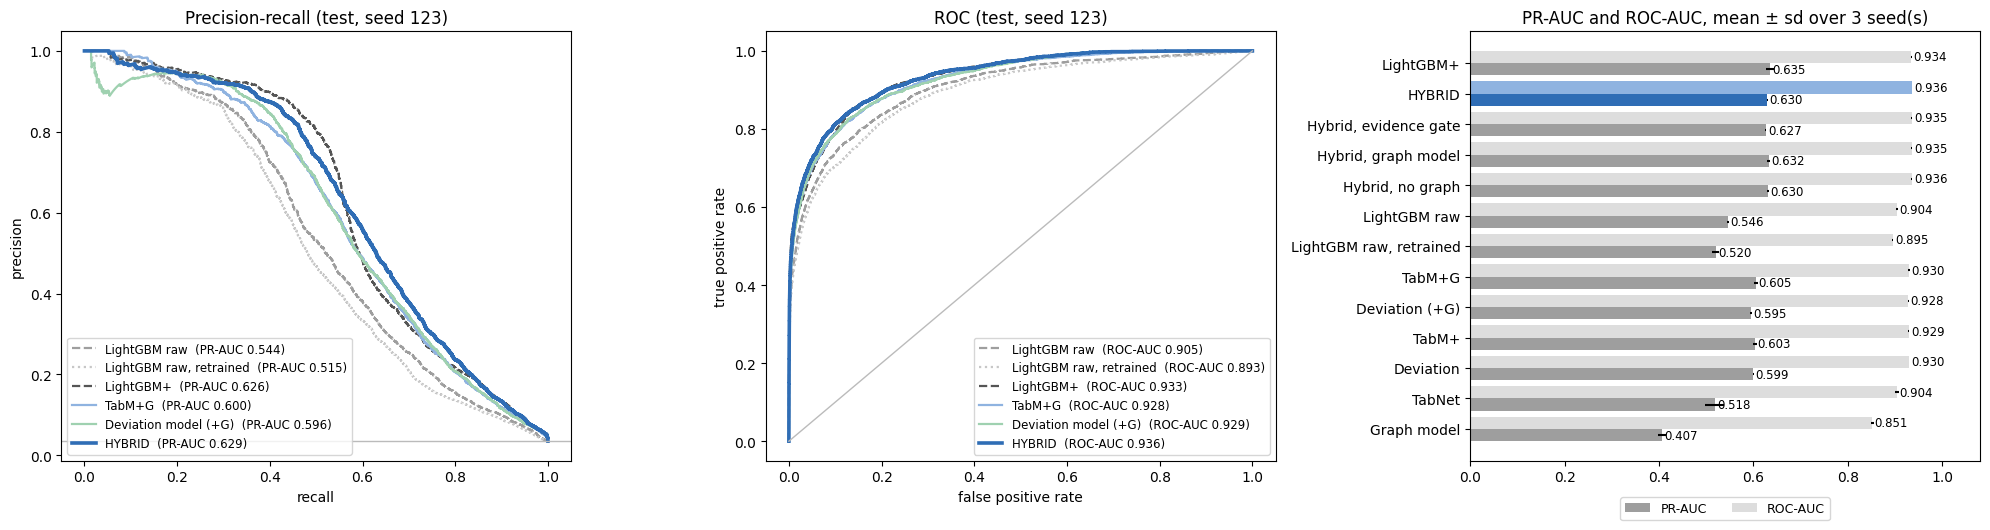

In [59]:
# ── 22 · Figures: PR and ROC curves (seed SEED) + PR-AUC / ROC-AUC bars (all stored seeds). Needs only cell 1 ──
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve
y, split = np.load(P('y.npy')), np.load(P('split.npy')); te = split == 3; yt = y[te]
CURVES = [('lgb_raw', 'LightGBM raw', '#9e9e9e', '--'), ('lgb_rt', 'LightGBM raw, retrained', '#c7c7c7', ':'),
          ('lgb_g', 'LightGBM+', '#555555', '--'), ('tabpg', 'TabM+G', '#8fb3e0', '-'),
          ('devg', 'Deviation model (+G)', '#9fd1b0', '-'), ('hyb', 'HYBRID', '#2f6db5', '-')]
fig, ax = plt.subplots(1, 3, figsize=(20, 5.4))
for key, name, c, ls in CURVES:
    if not has_score(key): continue
    p = score(key)[te]; ok = ~np.isnan(p); pr, rc, _ = precision_recall_curve(yt[ok], p[ok]); fp, tp, _ = roc_curve(yt[ok], p[ok])
    lw = 2.6 if key == 'hyb' else 1.6
    ax[0].plot(rc, pr, c=c, ls=ls, lw=lw, label=f'{name}  (PR-AUC {ap(yt[ok], p[ok]):.3f})')
    ax[1].plot(fp, tp, c=c, ls=ls, lw=lw, label=f'{name}  (ROC-AUC {auc(yt[ok], p[ok]):.3f})')
ax[0].axhline(yt.mean(), c='#bbbbbb', lw=1); ax[0].set(title=f'Precision-recall (test, seed {SEED})', xlabel='recall', ylabel='precision'); ax[0].legend(fontsize=8.5)
ax[1].plot([0, 1], [0, 1], c='#bbbbbb', lw=1); ax[1].set(title=f'ROC (test, seed {SEED})', xlabel='false positive rate', ylabel='true positive rate'); ax[1].legend(fontsize=8.5, loc='lower right')
M = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(P(STORE + 'seed_*_metrics.csv')))])
order = [k for k in ['gnn', 'tabnet', 'dev', 'tabp', 'devg', 'tabpg', 'lgb_rt', 'lgb_raw', 'hyb_nog', 'hyb_gexp', 'hyb_gate', 'hyb', 'lgb_g'] if k in M.model.values]
lab = {'gnn': 'Graph model', 'hyb_gate': 'Hybrid, evidence gate', 'tabnet': 'TabNet', 'dev': 'Deviation', 'tabp': 'TabM+', 'devg': 'Deviation (+G)', 'tabpg': 'TabM+G',
       'lgb_rt': 'LightGBM raw, retrained', 'lgb_raw': 'LightGBM raw', 'hyb_nog': 'Hybrid, no graph', 'hyb_gexp': 'Hybrid, graph model',
       'hyb': 'HYBRID', 'lgb_g': 'LightGBM+'}
s = M.groupby('model')[['pr', 'roc']].agg(['mean', 'std']).reindex(order); yy = np.arange(len(order))
ax[2].barh(yy - .2, s[('pr', 'mean')], .4, xerr=s[('pr', 'std')].fillna(0), color=['#2f6db5' if k == 'hyb' else '#9e9e9e' for k in order], label='PR-AUC')
ax[2].barh(yy + .2, s[('roc', 'mean')], .4, xerr=s[('roc', 'std')].fillna(0), color=['#8fb3e0' if k == 'hyb' else '#dddddd' for k in order], label='ROC-AUC')
for i, k in enumerate(order):
    ax[2].text(s.loc[k, ('pr', 'mean')] + .005, i - .2, f"{s.loc[k, ('pr', 'mean')]:.3f}", va='center', fontsize=8.5)
    ax[2].text(s.loc[k, ('roc', 'mean')] + .005, i + .2, f"{s.loc[k, ('roc', 'mean')]:.3f}", va='center', fontsize=8.5)
ax[2].set_yticks(yy, [lab[k] for k in order]); ax[2].set_xlim(0, 1.08); ax[2].legend(loc='upper center', bbox_to_anchor=(.5, -.07), ncol=2, fontsize=9)
ax[2].set_title(f'PR-AUC and ROC-AUC, mean ± sd over {M.seed.nunique()} seed(s)')
plt.tight_layout(); plt.savefig(P(STORE + 'results.png'), dpi=150, bbox_inches='tight'); plt.show()

In [60]:
# ── 23 · One block to copy back (the numbers for the method document) ──
M = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(P(STORE + 'seed_*_metrics.csv')))])
Qs = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(P(STORE + 'seed_*_questions.csv')))])
a = M.groupby('model')[['pr', 'roc', 'recall_1pct', 'pr_new', 'pr_few', 'pr_regular', 'train_min']].agg(['mean', 'std']).round(4)
a.columns = [f'{c}_{s}' for c, s in a.columns]
q = Qs.groupby(['section', 'question'], sort=False).agg(d_pr=('d_pr', 'mean'), pr_lo=('pr_lo', 'mean'), pr_hi=('pr_hi', 'mean'),
                                                         d_roc=('d_roc', 'mean'), n_seeds=('seed', 'nunique')).round(4)
print('SEEDS:', sorted(M.seed.unique().tolist())); print('\nMODELS'); print(a.to_csv()); print('COMPARISONS'); print(q.to_csv())
for kind in ['gate', 'calibration']:
    fs = sorted(glob.glob(P(STORE + f'seed_*_{kind}.csv')))
    if fs: print(kind.upper()); print(pd.concat([pd.read_csv(f) for f in fs]).to_csv(index=False))

SEEDS: [7, 42, 123]

MODELS
model,pr_mean,pr_std,roc_mean,roc_std,recall_1pct_mean,recall_1pct_std,pr_new_mean,pr_new_std,pr_few_mean,pr_few_std,pr_regular_mean,pr_regular_std,train_min_mean,train_min_std
dev,0.5995,0.0008,0.9299,0.0007,0.2651,0.0007,0.6566,0.0039,0.3229,0.0048,0.7558,0.0043,0.6789,0.0511
devg,0.5948,0.002,0.9282,0.001,0.2664,0.002,0.651,0.0013,0.3329,0.0059,0.7477,0.0055,0.6798,0.0416
gnn,0.4067,0.0086,0.8514,0.0032,0.2196,0.0059,0.5912,0.0122,0.2141,0.0079,0.0557,0.0013,3.179,0.0847
hyb,0.6296,0.0013,0.9364,0.0006,0.2681,0.0012,0.6818,0.0005,0.3745,0.0038,0.775,0.0014,,
hyb_both,0.6331,0.0014,0.9363,0.0007,0.2662,0.0015,0.6843,0.0015,0.3747,0.0035,0.7719,0.0023,,
hyb_gate,0.6266,0.001,0.9353,0.0005,0.2671,0.0015,0.678,0.0012,0.3743,0.0026,0.7688,0.0029,,
hyb_gexp,0.6324,0.003,0.9354,0.0008,0.2663,0.002,0.6866,0.0038,0.3715,0.0019,0.7659,0.004,,
hyb_nog,0.63,0.0022,0.9356,0.001,0.2671,0.0015,0.6846,0.0038,0.3712,0.0024,0.7701,0.0037,,
hyb_tabnet,0.6104,0.003,0.9305,0.